# Transfer Learning y Redes Neuronales Convolucionales para Visión por Computador

**Asignatura:** Análisis, Procesamiento y Aplicación de Inteligencia Artificial
**Curso:** Séptimo A — Carrera de Sistemas de Información, PUCE Sede Ambato
**Docente:** Ing. Alex Mora Parra, Mgtr.
**Duración:** 3 horas &nbsp;|&nbsp; **Entorno:** Google Colab con GPU &nbsp;|&nbsp; **Framework:** PyTorch + torchvision
**Versión:** Notebook de clase (explicaciones continuas; los ejercicios **TU TURNO** están reunidos en la Sección 12)

## Objetivos de aprendizaje

Al terminar la sesión, el estudiante será capaz de:

1. **Explicar** qué es el transfer learning, por qué funciona y cuándo conviene usar extracción de características o fine-tuning.
2. **Describir** cómo se representa y transforma una imagen antes de entrar a una red (tensores, canales, normalización, aumento de datos).
3. **Identificar** los componentes de una CNN (convolución, activación, pooling, normalización) y la evolución de las arquitecturas modernas (VGG, ResNet, MobileNet, EfficientNet, ConvNeXt).
4. **Ajustar** un modelo preentrenado con PyTorch, reconociendo los hiperparámetros que más influyen en el fine-tuning.
5. **Interpretar** las decisiones del modelo con Grad-CAM y analizar sus errores.



---
# 0. Arranque del entorno

**Paso 1 — Activar la GPU:** en Colab, menú **Entorno de ejecución → Cambiar tipo de entorno de ejecución → Acelerador por hardware: GPU (T4)** → Guardar.

**Paso 2 — Ejecutar las tres celdas siguientes** al inicio de la clase. La descarga del dataset tarda 1–3 minutos y queda lista mientras revisamos la teoría.

**¿Por qué GPU?** Entrenar una CNN implica millones de multiplicaciones de matrices por imagen. Una GPU ejecuta miles de estas operaciones en paralelo; en CPU, cada experimento de esta clase tardaría entre 20 y 50 veces más.

In [ ]:
# Gradio se usa en la demo final; PyTorch y torchvision ya vienen instalados en Colab
!pip install  gradio 

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
Failed to build PyTorch


  error: subprocess-exited-with-error
  
  × Building wheel for PyTorch (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [24 lines of output]
      Traceback (most recent call last):
        File "C:\Users\alexm\Desktop\PUCESA\Ambientes-virtuales\Ambiente-DataScience\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 353, in <module>
          main()
        File "C:\Users\alexm\Desktop\PUCESA\Ambientes-virtuales\Ambiente-DataScience\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 335, in main
          json_out['return_val'] = hook(**hook_input['kwargs'])
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\alexm\Desktop\PUCESA\Ambientes-virtuales\Ambiente-DataScience\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 251, in build_wheel
          return _build_backend().build_wheel(wheel_directory, config_settings,
                 ^^^^^^^^^^^^^

In [2]:
import os, time, random, copy, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, datasets
import torchvision.transforms as T

warnings.filterwarnings("ignore", category=UserWarning)


def fijar_semilla(seed=42):
    # Fija todas las fuentes de aleatoriedad para que los experimentos sean comparables
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


fijar_semilla(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"   # precisión mixta: más velocidad en GPU
NUM_WORKERS = 2                   # Colab ofrece 2 núcleos de CPU para cargar imágenes

plt.rcParams.update({"figure.dpi": 100, "axes.grid": False, "font.size": 10})

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Dispositivo: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("ATENCIÓN: no hay GPU activa. Revisa el Paso 1 antes de continuar.")

PyTorch 2.15.0+cpu | torchvision 0.29.2+cpu
Dispositivo: cpu
ATENCIÓN: no hay GPU activa. Revisa el Paso 1 antes de continuar.


In [3]:
# Oxford-IIIT Pets: 37 razas de perros y gatos, ~7.400 imágenes (Parkhi et al., 2012)
DATA_DIR = "./data"
pets_trainval = datasets.OxfordIIITPet(DATA_DIR, split="trainval", target_types="category", download=True)
pets_test = datasets.OxfordIIITPet(DATA_DIR, split="test", target_types="category", download=True)

CLASSES = pets_trainval.classes
print(f"Imágenes de entrenamiento (trainval): {len(pets_trainval)}")
print(f"Imágenes de prueba (test):            {len(pets_test)}")
print(f"Número de clases: {len(CLASSES)}")
print("Algunas clases:", CLASSES[:6], "...")

100%|██████████| 792M/792M [1:49:11<00:00, 121kB/s]   
100%|██████████| 19.2M/19.2M [02:04<00:00, 154kB/s] 


Imágenes de entrenamiento (trainval): 3680
Imágenes de prueba (test):            3669
Número de clases: 37
Algunas clases: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal'] ...


## 0.1 Antes de la teoría: ¿qué sabe un modelo que nunca vio este dataset?

Vamos a tomar una **ResNet18 entrenada en ImageNet** (1,2 millones de imágenes, 1.000 categorías) y mostrarle fotos de mascotas **sin entrenar nada**. ImageNet incluye unas 120 razas de perro y varios tipos de gato, pero no fue creado para nuestro problema.

**PREDICCIÓN:** ¿creen que acertará la raza? ¿Qué tan seguro estará?

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\alexm/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 10.6MB/s]


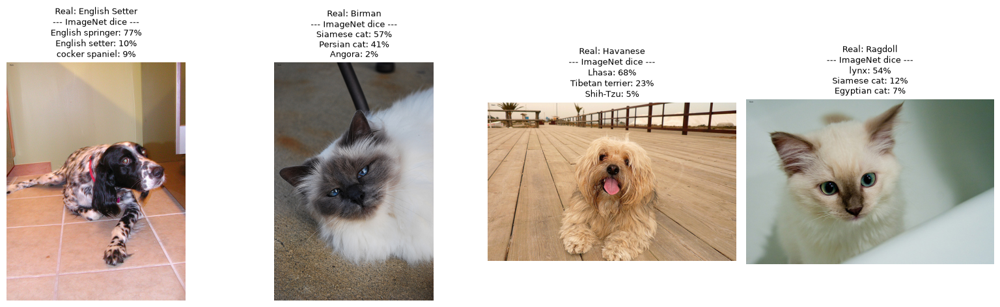

In [4]:
pesos_imagenet = models.ResNet18_Weights.DEFAULT
modelo_imagenet = models.resnet18(weights=pesos_imagenet).to(DEVICE).eval()
prep_imagenet = pesos_imagenet.transforms()          # el preprocesamiento con el que fue entrenado
CATEGORIAS_IMAGENET = pesos_imagenet.meta["categories"]


def top_imagenet(img, k=3):
    x = prep_imagenet(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        p = modelo_imagenet(x).softmax(dim=1)[0]
    vals, idx = p.topk(k)
    return [(CATEGORIAS_IMAGENET[i], v.item()) for v, i in zip(vals.cpu(), idx.cpu())]


rng = random.Random(7)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
for ax, i in zip(axes, rng.sample(range(len(pets_test)), 4)):
    img, y = pets_test[i]
    texto = "\n".join(f"{c[:20]}: {p:.0%}" for c, p in top_imagenet(img))
    ax.imshow(img)
    ax.set_title(f"Real: {CLASSES[y]}\n--- ImageNet dice ---\n{texto}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observación:** sin haber visto nunca este dataset, el modelo reconoce perros, gatos y muchas veces la raza correcta. Ese conocimiento (bordes, texturas, formas de orejas, hocicos, pelaje) **ya está en sus pesos**. La pregunta de la clase es: *¿cómo reutilizamos ese conocimiento para un problema nuevo, con pocos datos y poco tiempo de cómputo?* La respuesta es el **transfer learning**.

---
# 1. Transfer learning: conceptos y aplicaciones

## 1.1 ¿Qué es?

**Transfer learning** (aprendizaje por transferencia) es la técnica de **reutilizar un modelo entrenado en una tarea origen** (con muchos datos) como punto de partida para una **tarea destino** (normalmente con menos datos).

**Analogía:** quien ya sabe andar en bicicleta aprende a manejar una moto mucho más rápido que quien nunca se subió a dos ruedas. No empieza de cero: transfiere el equilibrio y la noción de dirección; solo aprende lo nuevo (acelerador, embrague).

**Definición formal** (Pan y Yang, 2010):

- Un **dominio** es $\mathcal{D} = \{\mathcal{X}, P(X)\}$: un espacio de características y su distribución (por ejemplo, fotos de 224×224 tomadas en internet).
- Una **tarea** es $\mathcal{T} = \{\mathcal{Y}, f(\cdot)\}$: un espacio de etiquetas y la función que queremos aprender.
- Dado un dominio/tarea origen $(\mathcal{D}_S, \mathcal{T}_S)$ y un dominio/tarea destino $(\mathcal{D}_T, \mathcal{T}_T)$, el transfer learning busca mejorar el aprendizaje de $f_T$ usando el conocimiento de $\mathcal{D}_S$ y $\mathcal{T}_S$, cuando $\mathcal{D}_S \neq \mathcal{D}_T$ o $\mathcal{T}_S \neq \mathcal{T}_T$.

En nuestra clase: **origen** = ImageNet (1.000 clases generales) → **destino** = 37 razas de mascotas.

## 1.2 ¿Por qué funciona?

Las redes profundas aprenden **representaciones jerárquicas**. Zeiler y Fergus (2014) y Yosinski et al. (2014) mostraron que:

| Profundidad de la capa | Qué detecta | ¿Qué tan transferible es? |
|---|---|---|
| Primeras capas | Bordes, colores, orientaciones | Muy general: sirve casi para cualquier imagen |
| Capas intermedias | Texturas, patrones, partes simples (ojos, ruedas) | General |
| Capas finales | Partes complejas y objetos completos | Específico de la tarea origen |
| Cabeza (clasificador) | Las 1.000 clases de ImageNet | No transferible: se reemplaza |

Por eso **reemplazamos la cabeza** y decidimos **cuánto del resto ajustar**.

## 1.3 Estrategias principales

| Estrategia | Qué se entrena | Cuándo usarla |
|---|---|---|
| **Extracción de características** (*feature extraction*) | Solo la cabeza nueva; el resto queda **congelado** | Pocos datos, dominio parecido al origen, poco cómputo |
| **Fine-tuning parcial** | Cabeza + últimos bloques | Datos moderados o dominio algo distinto |
| **Fine-tuning completo** | Toda la red, con learning rate pequeño | Bastantes datos o dominio bastante distinto |
| **Descongelado gradual** (*gradual unfreezing*) | Primero la cabeza, luego se van liberando capas | Para estabilizar el entrenamiento |
| **Learning rate discriminativo** | Toda la red, pero con LR menor en capas profundas preentrenadas | Casi siempre mejora el fine-tuning completo |
| **Adaptación de dominio** | Alinear distribuciones origen y destino | Mismo problema, datos de otra cámara/sensor/región |

## 1.4 ¿Cuál elijo? Matriz de decisión

| | **Dominio parecido** al origen | **Dominio diferente** al origen |
|---|---|---|
| **Pocos datos** (< 1.000 imágenes) | Extracción de características | Fine-tuning parcial con aumento de datos fuerte (riesgo alto) |
| **Muchos datos** | Fine-tuning completo con LR pequeño | Fine-tuning completo (o incluso entrenar desde cero si hay muchísimos datos) |

## 1.5 Riesgos que hay que conocer

- **Transferencia negativa:** si el origen es muy distinto (por ejemplo, fotos naturales → espectrogramas de audio o imágenes satelitales multiespectrales), el conocimiento previo puede estorbar.
- **Olvido catastrófico:** un learning rate demasiado alto destruye en pocas iteraciones los pesos preentrenados. Lo veremos en el laboratorio.
- **Preprocesamiento incoherente:** el modelo espera las mismas transformaciones con las que fue entrenado (tamaño, normalización). Cambiarlas degrada el rendimiento sin dar error.
- **Sesgos heredados y licencias:** el modelo trae los sesgos de su dataset original, y los pesos tienen licencias de uso que hay que revisar.

## 1.6 Aplicaciones

| Área | Ejemplo | Modelo origen típico |
|---|---|---|
| Salud | Detección de neumonía en radiografías, lesiones de piel, retinopatía diabética | CNN de ImageNet, modelos médicos preentrenados |
| Agricultura | Enfermedades en hojas de cacao, banano, papa o rosas (sectores clave en Ecuador) | ResNet, EfficientNet |
| Industria | Inspección de defectos en productos y soldaduras | MobileNet en dispositivos de borde |
| Seguridad vial | Detección de señales de tránsito y peatones | YOLO, Faster R-CNN |
| Comercio | Búsqueda de productos por foto, clasificación de catálogos | CLIP, ViT |
| Lenguaje | Clasificadores de emociones, chatbots (lo vimos con el fine-tuning de modelos de lenguaje) | BERT, GPT, Llama |
| Audio | Reconocimiento de voz, clasificación de sonidos | wav2vec, Whisper |

## 1.7 ¿Dónde encontrar modelos preentrenados?

- **torchvision.models** (el que usaremos): clasificación, detección y segmentación con pesos de ImageNet y COCO.
- **timm** (PyTorch Image Models): más de 1.000 arquitecturas de visión.
- **Hugging Face Hub**: visión, lenguaje y audio con el mismo flujo `from_pretrained`.
- **Keras Applications / TensorFlow Hub** para el ecosistema TensorFlow.

---
# 2. Cómo "ve" una computadora una imagen

## 2.1 Una imagen es un tensor de números

Para la computadora, una foto a color es una matriz tridimensional: **alto × ancho × canales**. Cada valor es la intensidad de un canal (rojo, verde o azul) en un píxel, normalmente un entero de 0 a 255 (`uint8`).

Clase: Abyssinian
Tipo de objeto: Image
Forma del arreglo (alto, ancho, canales): (500, 394, 3)
Tipo de dato: uint8 | mínimo: 0 | máximo: 255
Total de números que describen esta imagen: 591,000
Píxel central (R, G, B): [122  95  68]


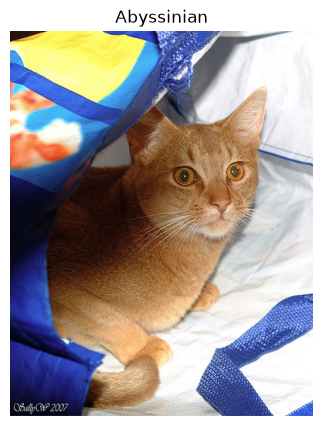

In [5]:
img_ejemplo, y_ejemplo = pets_trainval[0]
arr = np.array(img_ejemplo)

print(f"Clase: {CLASSES[y_ejemplo]}")
print(f"Tipo de objeto: {type(img_ejemplo).__name__}")
print(f"Forma del arreglo (alto, ancho, canales): {arr.shape}")
print(f"Tipo de dato: {arr.dtype} | mínimo: {arr.min()} | máximo: {arr.max()}")
print(f"Total de números que describen esta imagen: {arr.size:,}")
print(f"Píxel central (R, G, B): {arr[arr.shape[0] // 2, arr.shape[1] // 2]}")

plt.figure(figsize=(5, 5))
plt.imshow(img_ejemplo)
plt.title(CLASSES[y_ejemplo])
plt.axis("off")
plt.show()

## 2.2 Canales de color y escala de grises

- **RGB:** tres canales; cada color se forma mezclando intensidades de rojo, verde y azul.
- **Escala de grises:** un solo canal. La conversión estándar pondera los canales según la sensibilidad del ojo humano: $Y = 0{,}299R + 0{,}587G + 0{,}114B$.
- **HSV** (tono, saturación, valor): útil en visión clásica para segmentar por color; las CNN trabajan normalmente en RGB.

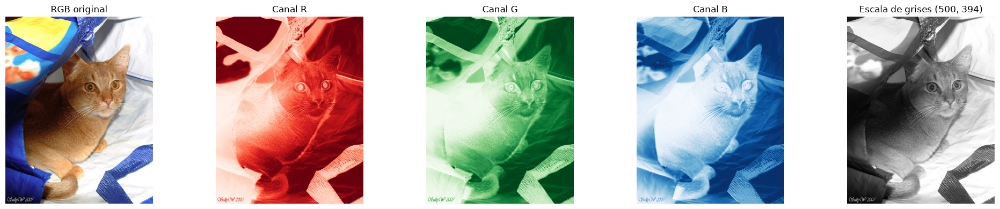

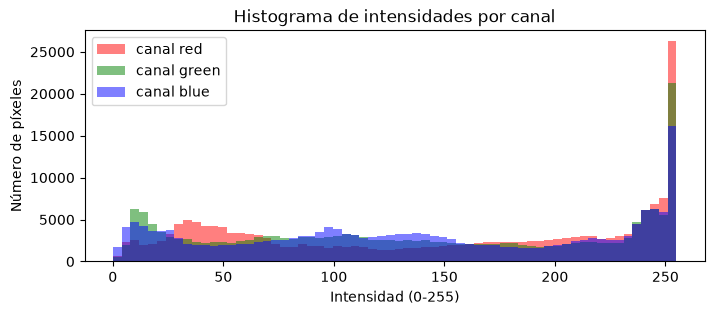

In [6]:
gris = np.array(img_ejemplo.convert("L"))

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(arr); axes[0].set_title("RGB original")
for i, (nombre, cmap) in enumerate([("Canal R", "Reds"), ("Canal G", "Greens"), ("Canal B", "Blues")]):
    axes[i + 1].imshow(arr[:, :, i], cmap=cmap)
    axes[i + 1].set_title(nombre)
axes[4].imshow(gris, cmap="gray"); axes[4].set_title(f"Escala de grises {gris.shape}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 3))
for i, c in enumerate(["red", "green", "blue"]):
    plt.hist(arr[:, :, i].ravel(), bins=64, color=c, alpha=0.5, label=f"canal {c}")
plt.title("Histograma de intensidades por canal")
plt.xlabel("Intensidad (0-255)")
plt.ylabel("Número de píxeles")
plt.legend()
plt.show()

## 2.3 Resolución: cuánta información conservamos

Las fotos del dataset tienen tamaños distintos, pero una CNN procesa lotes de imágenes del **mismo tamaño**. Reducir la resolución acelera el entrenamiento, pero se pierden detalles. Los modelos de ImageNet se entrenaron mayoritariamente con **224×224**.

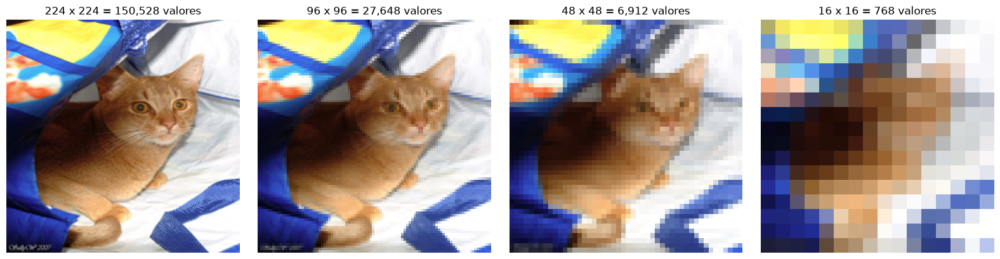

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, s in zip(axes, [224, 96, 48, 16]):
    ax.imshow(img_ejemplo.resize((s, s)))
    ax.set_title(f"{s} x {s} = {s * s * 3:,} valores")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2.4 La convolución: el operador central de la visión por computador

Una **convolución** desliza una pequeña matriz de pesos llamada **kernel** (o filtro) sobre la imagen y, en cada posición, calcula la suma de los productos elemento a elemento:

$$
S(i, j) = \sum_{m}\sum_{n} I(i + m,\; j + n)\, K(m, n)
$$

(Técnicamente las redes calculan una *correlación cruzada*, pero la convención es llamarla convolución.)

En visión clásica los kernels **se diseñan a mano** (Sobel para bordes, Gauss para suavizar). En una CNN los kernels **se aprenden** a partir de los datos. Veamos qué hacen algunos kernels clásicos:

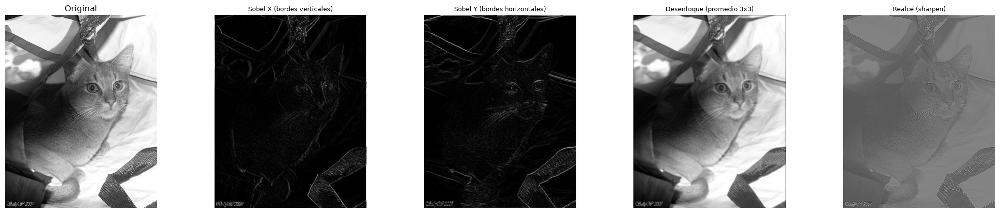

In [8]:
# La imagen en gris como tensor (lote=1, canales=1, alto, ancho) con valores en [0, 1]
x_gris = torch.tensor(gris, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

kernels = {
    "Sobel X (bordes verticales)": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
    "Sobel Y (bordes horizontales)": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
    "Desenfoque (promedio 3x3)": [[1 / 9] * 3] * 3,
    "Realce (sharpen)": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],
}

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
axes[0].imshow(gris, cmap="gray"); axes[0].set_title("Original")
for ax, (nombre, k) in zip(axes[1:], kernels.items()):
    K = torch.tensor(k, dtype=torch.float32).view(1, 1, 3, 3)
    salida = F.conv2d(x_gris, K, padding=1)[0, 0]
    ax.imshow(salida.abs() if "Sobel" in nombre else salida, cmap="gray")
    ax.set_title(nombre, fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2.5 Padding, stride y tamaño de salida

- **Kernel ($K$):** tamaño del filtro (3×3, 5×5, 7×7).
- **Padding ($P$):** ceros añadidos en los bordes para controlar el tamaño de salida.
- **Stride ($S$):** cuántos píxeles avanza el filtro en cada paso. Stride 2 reduce el tamaño a la mitad.

Para una entrada de ancho $W$, el ancho de salida es:

$$
O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1
$$

Esta fórmula es clave para diseñar redes y entender por qué las dimensiones cambian entre capas.

In [9]:
def tam_salida(W, K, P=0, S=1):
    return (W - K + 2 * P) // S + 1


# Verificación automática
assert tam_salida(224, 3, P=1, S=1) == 224, "Con kernel 3 y padding 1 el tamaño se conserva"
assert tam_salida(224, 7, P=3, S=2) == 112, "Así reduce la primera capa de ResNet"
assert tam_salida(112, 2, P=0, S=2) == 56, "Un max pooling 2x2 con stride 2"
print("Correcto: dominas la fórmula del tamaño de salida")

Correcto: dominas la fórmula del tamaño de salida


In [10]:
# Comprobación con una capa real de PyTorch: la primera convolución de ResNet
x = torch.randn(1, 3, 224, 224)
conv1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7, stride=2, padding=3)
print("Salida real de nn.Conv2d:", tuple(conv1(x).shape))
print("Según la fórmula:          (1, 64,", tam_salida(224, 7, 3, 2), ",", tam_salida(224, 7, 3, 2), ")")

Salida real de nn.Conv2d: (1, 64, 112, 112)
Según la fórmula:          (1, 64, 112 , 112 )


## 2.6 Pooling: resumir y reducir

El **pooling** reduce el tamaño espacial resumiendo regiones. El **max pooling** conserva el valor máximo de cada ventana: mantiene la señal más fuerte (por ejemplo, "aquí hay un borde") y aporta cierta tolerancia a pequeños desplazamientos.

In [11]:
m = torch.tensor([[1, 3, 2, 0],
                  [4, 6, 1, 1],
                  [0, 2, 9, 4],
                  [1, 1, 3, 5]], dtype=torch.float32).view(1, 1, 4, 4)

print("Entrada 4x4:\n", m[0, 0].int())
print("\nMax pooling 2x2 (stride 2):\n", F.max_pool2d(m, 2)[0, 0].int())
print("\nAverage pooling 2x2 (stride 2):\n", F.avg_pool2d(m, 2)[0, 0])

Entrada 4x4:
 tensor([[1, 3, 2, 0],
        [4, 6, 1, 1],
        [0, 2, 9, 4],
        [1, 1, 3, 5]], dtype=torch.int32)

Max pooling 2x2 (stride 2):
 tensor([[6, 2],
        [2, 9]], dtype=torch.int32)

Average pooling 2x2 (stride 2):
 tensor([[3.5000, 1.0000],
        [1.0000, 5.2500]])


## 2.7 El pipeline de transformaciones

Antes de entrar al modelo, cada imagen pasa por una cadena de transformaciones:

| Paso | Transformación | Por qué es necesaria |
|---|---|---|
| 1 | `Resize(256)` | Unifica tamaños; el lado menor pasa a 256 px conservando la proporción |
| 2 | `CenterCrop(224)` | Deja la imagen cuadrada en el tamaño que espera el modelo |
| 3 | `ToTensor()` | Convierte PIL (alto, ancho, canales, 0–255) en tensor (canales, alto, ancho, 0–1) |
| 4 | `Normalize(mean, std)` | Centra cada canal: $x' = (x - \mu) / \sigma$ |

**¿Por qué normalizar con la media y desviación de ImageNet?** Los pesos preentrenados aprendieron a trabajar con entradas centradas en esos valores: $\mu = (0{,}485;\ 0{,}456;\ 0{,}406)$ y $\sigma = (0{,}229;\ 0{,}224;\ 0{,}225)$. Si cambiamos la escala de la entrada, las activaciones internas se desplazan y el conocimiento transferido funciona peor. Además, entradas centradas en cero facilitan la optimización por gradiente.

In [12]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

t = T.ToTensor()(img_ejemplo)
print("Antes de ToTensor:", np.array(img_ejemplo).shape, np.array(img_ejemplo).dtype)
print("Después de ToTensor:", tuple(t.shape), t.dtype, f"rango [{t.min():.2f}, {t.max():.2f}]")
tn = T.Normalize(MEAN, STD)(t)
print("Media por canal tras normalizar:", [round(v, 2) for v in tn.mean(dim=(1, 2)).tolist()])
print("Desv. estándar por canal tras normalizar:", [round(v, 2) for v in tn.std(dim=(1, 2)).tolist()])

Antes de ToTensor: (500, 394, 3) uint8
Después de ToTensor: (3, 500, 394) torch.float32 rango [0.00, 1.00]
Media por canal tras normalizar: [0.43, 0.4, 0.6]
Desv. estándar por canal tras normalizar: [1.48, 1.47, 1.43]


El pipeline de **evaluación** (el que se usa en validación, prueba y producción) aplica los cuatro pasos de la tabla. No lleva aumento de datos: debe ser **determinista**, es decir, la misma imagen produce siempre el mismo tensor.

In [13]:
eval_tf = T.Compose([
    T.Resize(256),           # 1) lado menor a 256 px
    T.CenterCrop(224),       # 2) recorte central de 224 x 224
    T.ToTensor(),            # 3) PIL -> tensor float en [0, 1]
    T.Normalize(MEAN, STD),  # 4) normalizar con ImageNet     
])

x = eval_tf(img_ejemplo)
assert tuple(x.shape) == (3, 224, 224), f"La forma debería ser (3, 224, 224) y es {tuple(x.shape)}"
assert x.min() < 0, "Falta normalizar: después de Normalize hay valores negativos"
print("Pipeline de evaluación correcto:", tuple(x.shape))

Pipeline de evaluación correcto: (3, 224, 224)


## 2.8 Aumento de datos (*data augmentation*)

El aumento de datos genera **variaciones realistas** de cada imagen de entrenamiento en cada época: recortes, espejos, cambios de color. El modelo nunca ve dos veces exactamente la misma foto, lo que **reduce el sobreajuste** y lo hace robusto a condiciones reales.

| Transformación | Simula | Cuidado con |
|---|---|---|
| `RandomResizedCrop` | Distinto encuadre y distancia | Recortes que eliminan el objeto |
| `RandomHorizontalFlip` | Objeto mirando al otro lado | Texto, dígitos, señales de "gire a la izquierda" |
| `ColorJitter` | Cambios de iluminación | Problemas donde el color es la clase (madurez de una fruta) |
| `RandomRotation` | Cámara inclinada | Escenas con orientación fija |

**Regla de oro:** el aumento de datos se aplica **solo en entrenamiento**, nunca en validación ni prueba.

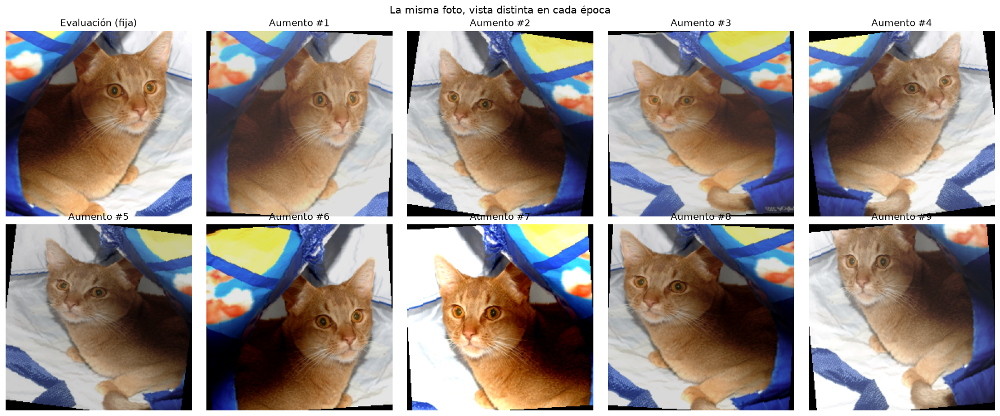

In [14]:
train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.6, 1.0)),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    T.RandomRotation(10),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])


def desnormalizar(x):
    # Revierte Normalize para poder mostrar el tensor como imagen
    x = x.detach().cpu() * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
axes[0, 0].imshow(desnormalizar(eval_tf(img_ejemplo))); axes[0, 0].set_title("Evaluación (fija)")
for k, ax in enumerate(axes.ravel()[1:]):
    ax.imshow(desnormalizar(train_tf(img_ejemplo)))
    ax.set_title(f"Aumento #{k + 1}")
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("La misma foto, vista distinta en cada época", fontsize=13)
plt.tight_layout()
plt.show()

---
# 3. Redes Neuronales Convolucionales (CNN)

## 3.1 ¿Por qué no usar una red densa (MLP) para imágenes?

Una red totalmente conectada trata cada píxel como una entrada independiente. Eso trae dos problemas:

1. **Explosión de parámetros:** cada neurona se conecta con todos los píxeles.
2. **No aprovecha la estructura espacial:** un borde en la esquina y el mismo borde en el centro se aprenden por separado.

Las CNN resuelven ambos con dos ideas:

- **Conectividad local:** cada neurona mira solo una ventana pequeña (su *campo receptivo*).
- **Pesos compartidos:** el mismo filtro recorre toda la imagen; lo que aprende en una zona sirve en todas (**equivarianza a la traslación**).

In [15]:
entrada = 224 * 224 * 3
densa = entrada * 1000 + 1000               # una capa densa con 1.000 neuronas
conv = 3 * 3 * 3 * 64 + 64                  # una capa conv con 64 filtros de 3x3
print(f"Capa densa (1.000 neuronas):     {densa:>13,} parámetros")
print(f"Capa convolucional (64 filtros): {conv:>13,} parámetros")
print(f"La densa tiene {densa / conv:,.0f} veces más parámetros")

Capa densa (1.000 neuronas):       150,529,000 parámetros
Capa convolucional (64 filtros):         1,792 parámetros
La densa tiene 84,001 veces más parámetros


## 3.2 Bloques de construcción de una CNN

| Bloque | Función | En PyTorch |
|---|---|---|
| Convolución | Detecta patrones locales con filtros aprendidos | `nn.Conv2d` |
| Activación | Introduce no linealidad (sin ella, toda la red sería una sola operación lineal) | `nn.ReLU`, `nn.GELU` |
| Normalización por lotes | Estabiliza y acelera el entrenamiento normalizando activaciones | `nn.BatchNorm2d` |
| Pooling | Reduce el tamaño espacial y resume información | `nn.MaxPool2d` |
| Pooling global promedio | Convierte cada mapa de características en un número | `nn.AdaptiveAvgPool2d(1)` |
| Dropout | Apaga neuronas al azar en entrenamiento para reducir sobreajuste | `nn.Dropout` |
| Capa densa final (cabeza) | Convierte las características en puntajes por clase | `nn.Linear` |

**Patrón típico:** `[Conv → BatchNorm → ReLU] × n → Pool` repetido varias veces, de modo que el tamaño espacial **disminuye** mientras el número de canales **aumenta** (menos "dónde", más "qué").

## 3.3 Una CNN pequeña, capa por capa

In [16]:
class MiniCNN(nn.Module):
    def __init__(self, num_clases=37):
        super().__init__()
        self.caracteristicas = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.pool_global = nn.AdaptiveAvgPool2d(1)
        self.cabeza = nn.Linear(128, num_clases)

    def forward(self, x):
        x = self.caracteristicas(x)
        x = self.pool_global(x).flatten(1)
        return self.cabeza(x)


mini = MiniCNN()
x = torch.randn(1, 3, 224, 224)
print(f"{'Capa':<22}{'Forma de salida':<24}{'Parámetros':>12}")
print("-" * 58)
for capa in list(mini.caracteristicas) + [mini.pool_global, nn.Flatten(1), mini.cabeza]:
    x = capa(x)
    n = sum(p.numel() for p in capa.parameters())
    print(f"{capa.__class__.__name__:<22}{str(tuple(x.shape)):<24}{n:>12,}")
print("-" * 58)
print(f"Total de parámetros: {sum(p.numel() for p in mini.parameters()):,}")

Capa                  Forma de salida           Parámetros
----------------------------------------------------------
Conv2d                (1, 32, 224, 224)                896
BatchNorm2d           (1, 32, 224, 224)                 64
ReLU                  (1, 32, 224, 224)                  0
MaxPool2d             (1, 32, 112, 112)                  0
Conv2d                (1, 64, 112, 112)             18,496
BatchNorm2d           (1, 64, 112, 112)                128
ReLU                  (1, 64, 112, 112)                  0
MaxPool2d             (1, 64, 56, 56)                    0
Conv2d                (1, 128, 56, 56)              73,856
BatchNorm2d           (1, 128, 56, 56)                 256
ReLU                  (1, 128, 56, 56)                   0
MaxPool2d             (1, 128, 28, 28)                   0
AdaptiveAvgPool2d     (1, 128, 1, 1)                     0
Flatten               (1, 128)                           0
Linear                (1, 37)                        4,7

Observen cómo el tamaño espacial baja de 224 → 112 → 56 → 28 mientras los canales suben de 3 → 32 → 64 → 128.

## 3.4 ¿Qué aprendió una CNN real? Los filtros de la primera capa

La primera capa de la ResNet18 preentrenada tiene 64 filtros de 7×7×3. Al visualizarlos aparecen **detectores de bordes en distintas orientaciones y detectores de color**: los mismos que en visión clásica se diseñaban a mano, pero aprendidos automáticamente.

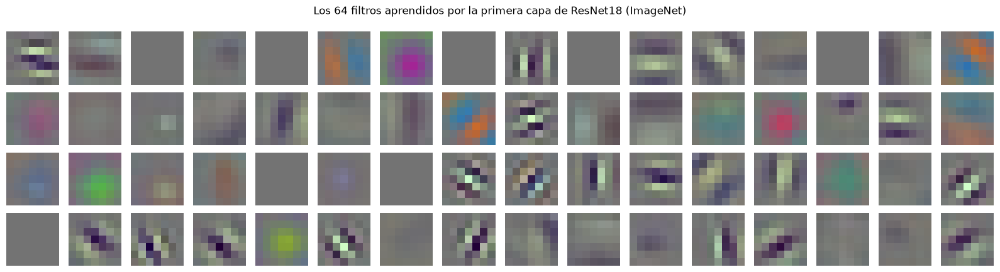

In [17]:
filtros = modelo_imagenet.conv1.weight.detach().cpu()          # (64, 3, 7, 7)
filtros = (filtros - filtros.min()) / (filtros.max() - filtros.min())

fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(filtros[i].permute(1, 2, 0).numpy())
    ax.axis("off")
plt.suptitle("Los 64 filtros aprendidos por la primera capa de ResNet18 (ImageNet)")
plt.tight_layout()
plt.show()

## 3.5 Mapas de características: la jerarquía en acción

Capturamos la salida de varias capas con *hooks* (ganchos que se ejecutan durante el `forward`). En las primeras capas los mapas se parecen a la imagen (bordes); en las profundas son pequeños y abstractos (partes y conceptos).

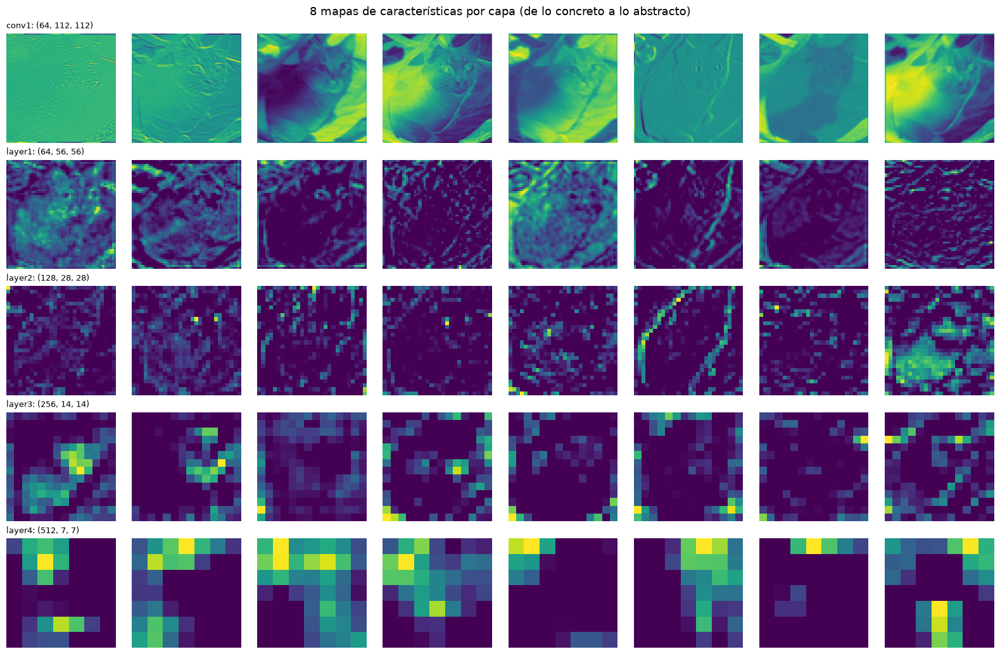

In [18]:
activaciones = {}


def guardar(nombre):
    def hook(modulo, entrada, salida):
        activaciones[nombre] = salida.detach().cpu()
    return hook


capas_a_ver = ["conv1", "layer1", "layer2", "layer3", "layer4"]
ganchos = [getattr(modelo_imagenet, n).register_forward_hook(guardar(n)) for n in capas_a_ver]
with torch.no_grad():
    modelo_imagenet(eval_tf(img_ejemplo).unsqueeze(0).to(DEVICE))
for g in ganchos:
    g.remove()

fig, axes = plt.subplots(len(capas_a_ver), 8, figsize=(16, 10.5))
for fila, nombre in enumerate(capas_a_ver):
    a = activaciones[nombre][0]
    for col in range(8):
        axes[fila, col].imshow(a[col], cmap="viridis")
        axes[fila, col].axis("off")
    axes[fila, 0].set_title(f"{nombre}: {tuple(a.shape)}", fontsize=9, loc="left")
plt.suptitle("8 mapas de características por capa (de lo concreto a lo abstracto)", fontsize=13)
plt.tight_layout()
plt.show()

---
# 4. CNN avanzadas y aplicaciones en visión

## 4.1 Evolución de las arquitecturas

| Año | Arquitectura | Idea clave | Parámetros | Top-1 ImageNet* |
|---|---|---|---|---|
| 1998 | LeNet-5 | Primera CNN práctica (lectura de cheques) | 60 mil | — |
| 2012 | AlexNet | ReLU, dropout y entrenamiento en GPU; inicia la era del deep learning | 61,1 M | 56,5 % |
| 2014 | VGG-16 | Solo convoluciones 3×3 apiladas; simple pero pesada | 138,4 M | 71,6 % |
| 2014 | GoogLeNet / Inception | Ramas paralelas con filtros de distinto tamaño | 6,6 M | 69,8 % |
| 2015 | **ResNet** | **Conexiones residuales**: permiten redes de 50, 101 o 152 capas | 11,7 M (R18) / 25,6 M (R50) | 69,8 % / 80,9 % |
| 2017–19 | **MobileNet** v1–v3 | Convoluciones separables en profundidad; pensada para celulares | 5,5 M (v3-L) | 75,3 % |
| 2019 | **EfficientNet** | Escalado compuesto de profundidad, ancho y resolución | 5,3 M (B0) | 77,7 % |
| 2020 | Vision Transformer (ViT) | Atención sobre parches de imagen, sin convoluciones | 86,6 M (B/16) | 81,1 % |
| 2022 | **ConvNeXt** | CNN "modernizada" con ideas de los Transformers | 28,6 M (Tiny) | 82,5 % |

\*Precisión top-1 en ImageNet reportada en la documentación de torchvision para los pesos que usaremos.

## 4.2 ResNet: la conexión residual

Antes de 2015, añadir capas a una red podía **empeorar** su rendimiento: los gradientes se desvanecían al retropropagarse por muchas capas. ResNet propuso que cada bloque aprenda solo la **diferencia** (el residuo) respecto a su entrada:

$$
\mathbf{y} = \mathcal{F}(\mathbf{x}) + \mathbf{x}
$$

El término $+\mathbf{x}$ es un "atajo" (*skip connection*) por donde el gradiente fluye directamente hacia atrás. Si un bloque no aporta, le basta con aprender $\mathcal{F}(\mathbf{x}) \approx 0$. Esta idea está presente en casi todas las arquitecturas modernas, incluidos los Transformers que vimos en clases anteriores.

## 4.3 MobileNet: convoluciones separables en profundidad

Una convolución estándar mezcla espacio y canales a la vez. MobileNet la divide en dos pasos:

1. **Depthwise:** un filtro $K \times K$ por cada canal de entrada (solo espacio).
2. **Pointwise:** una convolución $1 \times 1$ que mezcla los canales.

Parámetros (sin sesgo):

- Estándar: $K \cdot K \cdot C_{in} \cdot C_{out}$
- Separable: $K \cdot K \cdot C_{in} + C_{in} \cdot C_{out}$

In [19]:
def params_conv_estandar(c_in, c_out, k):
    return k * k * c_in * c_out


def params_conv_separable(c_in, c_out, k):
    return k * k * c_in + c_in * c_out


# Verificación contra PyTorch
c_in, c_out, k = 128, 256, 3
real_std = sum(p.numel() for p in nn.Conv2d(c_in, c_out, k, bias=False).parameters())
real_sep = sum(p.numel() for p in nn.Sequential(
    nn.Conv2d(c_in, c_in, k, groups=c_in, bias=False),   # depthwise
    nn.Conv2d(c_in, c_out, 1, bias=False)                # pointwise
).parameters())
assert params_conv_estandar(c_in, c_out, k) == real_std
assert params_conv_separable(c_in, c_out, k) == real_sep
print(f"Estándar: {real_std:,} | Separable: {real_sep:,} | Ahorro: {real_std / real_sep:.1f} veces")

Estándar: 294,912 | Separable: 33,920 | Ahorro: 8.7 veces


## 4.4 EfficientNet, ConvNeXt y Vision Transformers

- **EfficientNet** (Tan y Le, 2019): en lugar de agrandar la red "a ojo", escala **al mismo tiempo** profundidad, ancho y resolución con un coeficiente compuesto. B0 es la versión base; B1–B7 son versiones escaladas.
- **ConvNeXt** (Liu et al., 2022): toma una ResNet y la moderniza con decisiones inspiradas en los Transformers (kernels 7×7, LayerNorm, GELU, menos activaciones). Demuestra que las CNN siguen siendo competitivas.
- **Vision Transformer** (Dosovitskiy et al., 2020): divide la imagen en parches de 16×16, los trata como "tokens" y aplica la misma atención que vimos en los modelos de lenguaje. Necesita más datos para preentrenarse, pero transfiere muy bien.

**Comparemos el tamaño real** de las arquitecturas disponibles en torchvision (se instancian sin pesos, así que no descarga nada):

,Arquitectura,Parámetros (M),Top-1 ImageNet (%)
0,AlexNet,61.1,56.5
1,VGG-16,138.4,71.6
2,ResNet18,11.7,69.8
3,ResNet50,25.6,80.9
4,MobileNetV3-L,5.5,75.3
5,EfficientNet-B0,5.3,77.7
6,ConvNeXt-Tiny,28.6,82.5


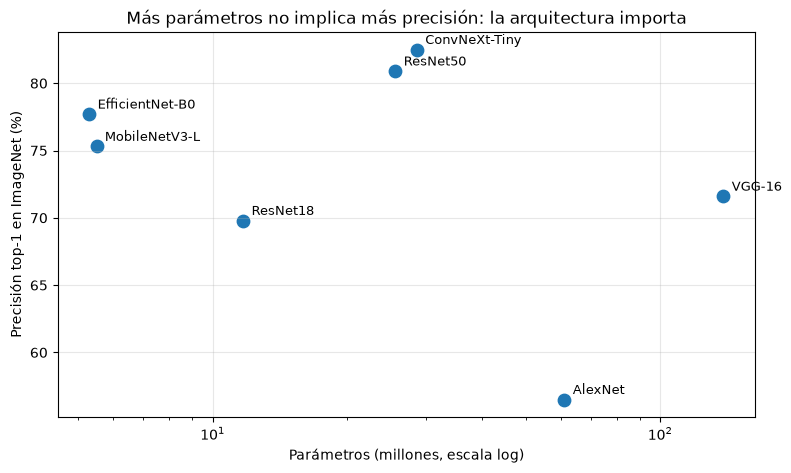

In [20]:
arquitecturas = {
    "AlexNet": models.alexnet, "VGG-16": models.vgg16, "ResNet18": models.resnet18,
    "ResNet50": models.resnet50, "MobileNetV3-L": models.mobilenet_v3_large,
    "EfficientNet-B0": models.efficientnet_b0, "ConvNeXt-Tiny": models.convnext_tiny,
}
top1 = {"AlexNet": 56.5, "VGG-16": 71.6, "ResNet18": 69.8, "ResNet50": 80.9,
        "MobileNetV3-L": 75.3, "EfficientNet-B0": 77.7, "ConvNeXt-Tiny": 82.5}

filas = []
for nombre, constructor in arquitecturas.items():
    m = constructor(weights=None)
    filas.append({"Arquitectura": nombre,
                  "Parámetros (M)": round(sum(p.numel() for p in m.parameters()) / 1e6, 1),
                  "Top-1 ImageNet (%)": top1[nombre]})
    del m
tabla_arq = pd.DataFrame(filas)
display(tabla_arq)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(tabla_arq["Parámetros (M)"], tabla_arq["Top-1 ImageNet (%)"], s=80)
for _, r in tabla_arq.iterrows():
    ax.annotate(r["Arquitectura"], (r["Parámetros (M)"], r["Top-1 ImageNet (%)"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Parámetros (millones, escala log)")
ax.set_ylabel("Precisión top-1 en ImageNet (%)")
ax.set_title("Más parámetros no implica más precisión: la arquitectura importa")
ax.grid(alpha=0.3)
plt.show()

## 4.5 Más allá de la clasificación

| Tarea | Pregunta que responde | Salida | Modelos representativos |
|---|---|---|---|
| **Clasificación** | ¿Qué hay en la imagen? | Una etiqueta | ResNet, EfficientNet, ConvNeXt, ViT |
| **Detección de objetos** | ¿Qué objetos hay y dónde? | Cajas + etiquetas + confianza | Faster R-CNN, YOLO, DETR |
| **Segmentación semántica** | ¿A qué clase pertenece cada píxel? | Máscara por clase | U-Net, DeepLab |
| **Segmentación de instancias** | ¿Qué píxeles son de cada objeto individual? | Una máscara por objeto | Mask R-CNN, SAM |
| **Estimación de pose** | ¿Dónde están las articulaciones? | Puntos clave | Keypoint R-CNN, OpenPose |

Todas usan una **CNN preentrenada como "columna vertebral"** (*backbone*): es transfer learning otra vez. Veamos dos de ellas en acción sobre fotos del dataset, con modelos preentrenados en COCO y Pascal VOC:

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to C:\Users\alexm/.cache\torch\hub\checkpoints\fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:02<00:00, 29.2MB/s]


Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to C:\Users\alexm/.cache\torch\hub\checkpoints\deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:01<00:00, 27.5MB/s]


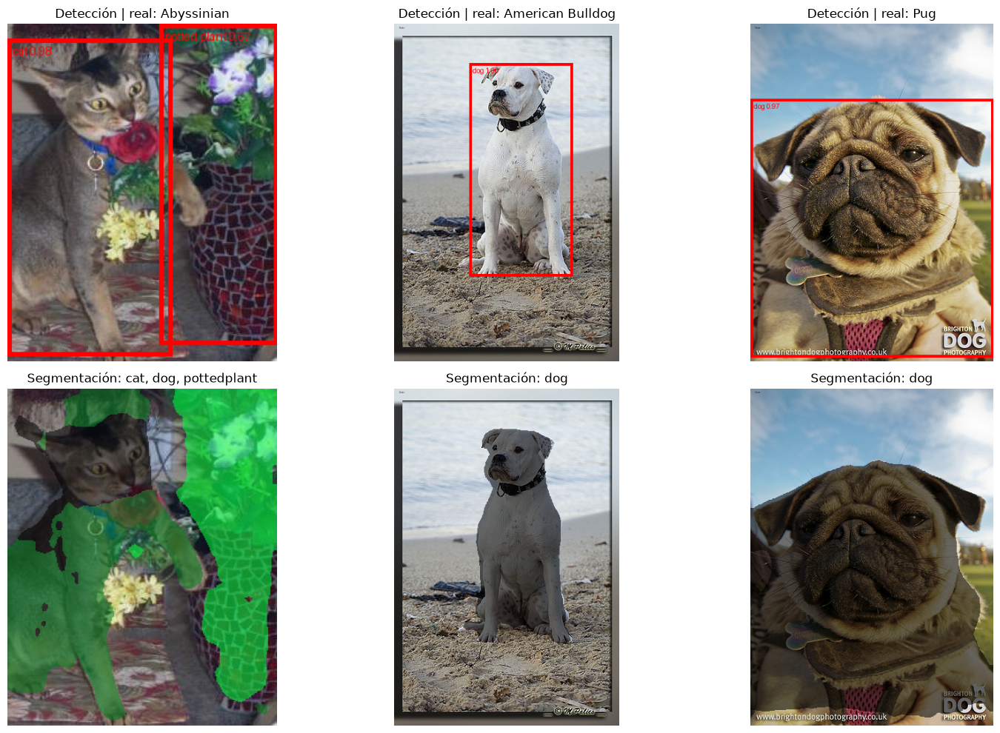

In [21]:
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks

pesos_det = models.detection.FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
detector = models.detection.fasterrcnn_mobilenet_v3_large_fpn(weights=pesos_det).to(DEVICE).eval()
pesos_seg = models.segmentation.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
segmentador = models.segmentation.deeplabv3_mobilenet_v3_large(weights=pesos_seg).to(DEVICE).eval()

cat_det = pesos_det.meta["categories"]
cat_seg = pesos_seg.meta["categories"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for col, idx in enumerate([3, 120, 2500]):
    img, y = pets_test[idx]
    img_u8 = T.functional.pil_to_tensor(img)                       # uint8 (C, H, W)

    # Detección de objetos
    with torch.no_grad():
        det = detector([pesos_det.transforms()(img_u8).to(DEVICE)])[0]
    keep = det["scores"] > 0.6
    etiquetas = [f"{cat_det[l]} {s:.2f}" for l, s in zip(det["labels"][keep].cpu(), det["scores"][keep].cpu())]
    cajas = draw_bounding_boxes(img_u8, det["boxes"][keep].cpu(), labels=etiquetas, colors="red", width=4)
    axes[0, col].imshow(cajas.permute(1, 2, 0))
    axes[0, col].set_title(f"Detección | real: {CLASSES[y]}")

    # Segmentación semántica
    with torch.no_grad():
        out = segmentador(pesos_seg.transforms()(img_u8).unsqueeze(0).to(DEVICE))["out"]
    mascara = out.argmax(1)[0].cpu()
    mascara = T.functional.resize(mascara.unsqueeze(0), list(img_u8.shape[1:]),
                                  interpolation=T.InterpolationMode.NEAREST)[0]
    clases_presentes = [c for c in mascara.unique().tolist() if c != 0]
    masks = torch.stack([mascara == c for c in clases_presentes]) if clases_presentes else torch.zeros(1, *mascara.shape, dtype=torch.bool)
    seg = draw_segmentation_masks(img_u8, masks, alpha=0.55)
    axes[1, col].imshow(seg.permute(1, 2, 0))
    axes[1, col].set_title("Segmentación: " + ", ".join(cat_seg[c] for c in clases_presentes))
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## Receso (10 minutos)

Al volver comienza la parte práctica. Si la descarga del dataset no terminó, verifiquen la celda de la Sección 0.

---
# 5. Práctica: el pipeline de datos

## 5.1 Exploración rápida del dataset

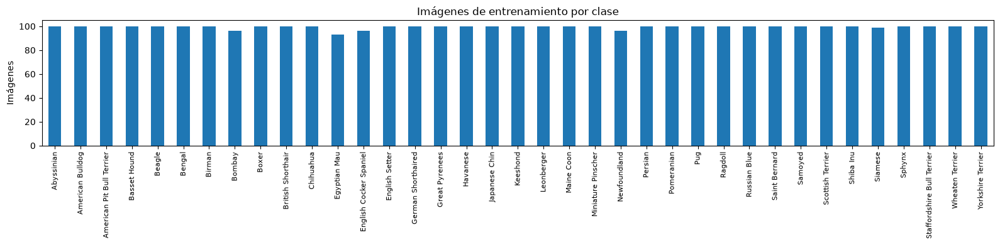

Mínimo por clase: 93 | máximo: 100 -> dataset prácticamente balanceado


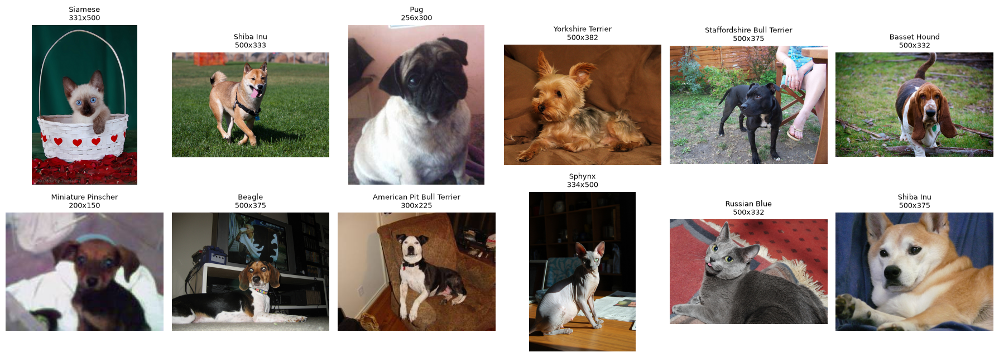

In [22]:
def etiquetas_de(base):
    # ImageFolder guarda las etiquetas en .targets; OxfordIIITPet en ._labels
    return list(base.targets) if hasattr(base, "targets") else list(base._labels)


conteo = pd.Series(etiquetas_de(pets_trainval)).value_counts().sort_index()
conteo.index = [CLASSES[i] for i in conteo.index]

plt.figure(figsize=(16, 4))
conteo.plot(kind="bar")
plt.title("Imágenes de entrenamiento por clase")
plt.ylabel("Imágenes")
plt.xticks(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Mínimo por clase: {conteo.min()} | máximo: {conteo.max()} -> dataset prácticamente balanceado")

rng = random.Random(0)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for ax, i in zip(axes.ravel(), rng.sample(range(len(pets_trainval)), 12)):
    img, y = pets_trainval[i]
    ax.imshow(img)
    ax.set_title(f"{CLASSES[y]}\n{img.size[0]}x{img.size[1]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observación:** las imágenes tienen tamaños y proporciones distintos, fondos variados y a veces más de un animal. Por eso necesitamos el pipeline de transformaciones de la Sección 2.

## 5.2 Particiones: entrenamiento, validación y prueba

| Partición | Origen | Uso |
|---|---|---|
| **Entrenamiento** | `trainval` completo (3.680) | Ajustar los pesos |
| **Validación** | 1.000 imágenes de `test` | Comparar experimentos y elegir hiperparámetros |
| **Prueba final** | Resto de `test` (~2.670) | Se usa **una sola vez**, en la competencia |

**¿Por qué separar validación y prueba?** Si elegimos la configuración mirando el conjunto de prueba, ese número deja de ser una estimación honesta: habremos "sobreajustado" nuestras decisiones a él.

In [23]:
N_VAL = 1000
perm = np.random.RandomState(42).permutation(len(pets_test))
idx_val, idx_test = perm[:N_VAL].tolist(), perm[N_VAL:].tolist()
idx_train = list(range(len(pets_trainval)))

print(f"Entrenamiento: {len(idx_train)} | Validación: {len(idx_val)} | Prueba final: {len(idx_test)}")

Entrenamiento: 3680 | Validación: 1000 | Prueba final: 2669


## 5.3 Dataset, transformaciones y DataLoaders

- **`Dataset`**: sabe devolver *una* muestra `(imagen, etiqueta)`.
- **`DataLoader`**: agrupa muestras en **lotes** (*batches*), las mezcla en cada época y las carga en paralelo con varios procesos (`num_workers`).

Escribimos un envoltorio que aplica una transformación distinta según la partición, de forma que el mismo dataset base sirva para entrenamiento (con aumento) y evaluación (sin aumento).

In [ ]:
class SubconjuntoTransformado(Dataset):
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, list(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, y = self.base[self.indices[i]]
        return self.transform(img), y


def construir_transformaciones(img_size=224, augment=True):
    resize = int(round(img_size * 256 / 224))
    evaluacion = T.Compose([T.Resize(resize), T.CenterCrop(img_size), T.ToTensor(), T.Normalize(MEAN, STD)])
    if not augment:
        return evaluacion, evaluacion
    entrenamiento = T.Compose([
        T.RandomResizedCrop(img_size, scale=(0.6, 1.0)),
        T.RandomHorizontalFlip(),
        T.ColorJitter(0.3, 0.3, 0.3),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
    ])
    return entrenamiento, evaluacion


def construir_datos(base_train, idx_train, base_val, idx_val, classes, base_test=None, idx_test=None):
    # Empaqueta todo lo necesario para entrenar; sirve para Pets y para un dataset propio
    return dict(base_train=base_train, idx_train=list(idx_train), base_val=base_val, idx_val=list(idx_val),
                base_test=base_test, idx_test=list(idx_test) if idx_test is not None else None,
                classes=list(classes), labels_train=etiquetas_de(base_train))


def muestrear_por_clase(indices, etiquetas, k, seed=42):
    # Toma k índices por clase (para simular escenarios con pocos datos)
    rng = random.Random(seed)
    por_clase = {}
    for i in indices:
        por_clase.setdefault(etiquetas[i], []).append(i)
    return [i for lista in por_clase.values() for i in rng.sample(lista, min(k, len(lista)))]


def crear_loader(base, indices, transform, batch_size, shuffle):
    ds = SubconjuntoTransformado(base, indices, transform)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=USE_AMP, drop_last=shuffle and len(ds) > 2 * batch_size)


DATA_PETS = construir_datos(pets_trainval, idx_train, pets_test, idx_val, CLASSES, pets_test, idx_test)

# Revisemos un lote
tf_tr, _ = construir_transformaciones(224)
xb, yb = next(iter(crear_loader(pets_trainval, idx_train, tf_tr, 16, True)))
print("Lote de imágenes:", tuple(xb.shape), "-> (lote, canales, alto, ancho)")
print("Lote de etiquetas:", tuple(yb.shape), yb[:8].tolist())

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, xi, yi in zip(axes.ravel(), xb, yb):
    ax.imshow(desnormalizar(xi))
    ax.set_title(CLASSES[yi][:14], fontsize=8)
    ax.axis("off")
plt.suptitle("Así ve el modelo un lote de entrenamiento (con aumento de datos)")
plt.tight_layout()
plt.show()

---
# 6. Motor de entrenamiento para transfer learning

## 6.1 Cargar un modelo preentrenado y reemplazar la cabeza

Cada arquitectura nombra distinto su clasificador final: en ResNet es `fc`; en MobileNet, EfficientNet y ConvNeXt es `classifier`. El procedimiento siempre es el mismo:

1. Cargar la red con pesos de ImageNet.
2. Reemplazar la última capa `Linear` (1.000 salidas) por una nueva con **tantas salidas como clases tenga nuestro problema** (37). Sus pesos empiezan aleatorios.

Detalle: en MobileNetV3 el bloque `classifier` incluye además una capa densa intermedia (960 → 1.280) preentrenada; en este notebook la tratamos como parte de la cabeza, por eso en extracción de características esa arquitectura entrena más parámetros que las demás.

In [ ]:
ARQUITECTURAS = {
    # nombre: (constructor, pesos, atributo de la cabeza)
    "resnet18": (models.resnet18, models.ResNet18_Weights.DEFAULT, "fc"),
    "resnet50": (models.resnet50, models.ResNet50_Weights.DEFAULT, "fc"),
    "mobilenet_v3_large": (models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.DEFAULT, "classifier"),
    "efficientnet_b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.DEFAULT, "classifier"),
    "convnext_tiny": (models.convnext_tiny, models.ConvNeXt_Tiny_Weights.DEFAULT, "classifier"),
}

# Último bloque convolucional de cada arquitectura (se descongela en fine-tuning parcial)
BLOQUE_FINAL = {
    "resnet18": lambda m: m.layer4,
    "resnet50": lambda m: m.layer4,
    "mobilenet_v3_large": lambda m: m.features[-4:],
    "efficientnet_b0": lambda m: m.features[-3:],
    "convnext_tiny": lambda m: m.features[-2:],
}

# Capa donde Grad-CAM mira las activaciones (Sección 10)
CAPA_GRADCAM = {
    "resnet18": lambda m: m.layer4[-1],
    "resnet50": lambda m: m.layer4[-1],
    "mobilenet_v3_large": lambda m: m.features[-1],
    "efficientnet_b0": lambda m: m.features[-1],
    "convnext_tiny": lambda m: m.features[-1],
}


def obtener_cabeza(model, arch):
    return getattr(model, ARQUITECTURAS[arch][2])


def construir_modelo(arch, num_clases, pretrained=True, dropout=0.0):
    constructor, pesos, nombre_cabeza = ARQUITECTURAS[arch]
    model = constructor(weights=pesos if pretrained else None)
    if nombre_cabeza == "fc":
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, num_clases))
    else:
        ultima = model.classifier[-1]
        model.classifier[-1] = nn.Linear(ultima.in_features, num_clases)
        if dropout > 0:
            model.classifier.insert(len(model.classifier) - 1, nn.Dropout(dropout))
    return model


def contar_parametros(model):
    total = sum(p.numel() for p in model.parameters())
    entrenables = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, entrenables


m = construir_modelo("resnet18", len(CLASSES))
print("Cabeza original de ResNet18: Linear(512 -> 1000)")
print("Cabeza nueva:", m.fc)

## 6.2 Congelar y descongelar capas

En PyTorch, cada parámetro tiene el atributo `requires_grad`. Si es `False`, el optimizador **no lo modifica**: la capa queda **congelada**.

| Estrategia | Backbone | Último bloque | Cabeza |
|---|---|---|---|
| `"feature_extraction"` | congelado | congelado | entrena |
| `"partial"` | congelado | entrena | entrena |
| `"full"` | entrena | entrena | entrena |

La función recorre los parámetros en tres pasos: estado por defecto, bloque final (solo en `partial`) y cabeza.

In [ ]:
def configurar_entrenables(model, arch, strategy):
    # Paso 1: estado por defecto de TODOS los parámetros
    for p in model.parameters():
        p.requires_grad = (strategy == "full")

    # Paso 2: en fine-tuning parcial se descongela el último bloque convolucional
    if strategy == "partial":
        for p in BLOQUE_FINAL[arch](model).parameters():
            p.requires_grad = True

    # Paso 3: la cabeza nueva SIEMPRE se entrena (sus pesos son aleatorios)
    for p in obtener_cabeza(model, arch).parameters():
        p.requires_grad = True


# Verificación
for estrategia in ["feature_extraction", "partial", "full"]:
    m = construir_modelo("resnet18", len(CLASSES))
    configurar_entrenables(m, "resnet18", estrategia)
    total, entrenables = contar_parametros(m)
    print(f"{estrategia:<20} entrenables: {entrenables:>11,} de {total:,} ({entrenables / total:.1%})")

**Resultado esperado:** en extracción de características solo se entrena alrededor del 0,2 % de la red (la cabeza: 512 × 37 + 37 = 18.981 parámetros). Por eso es tan rápido y funciona con pocos datos.

## 6.3 Learning rate discriminativo: grupos de parámetros

La cabeza nueva parte de pesos aleatorios y necesita aprender rápido (**LR alto**). El backbone ya tiene buenos pesos y solo debe ajustarse un poco (**LR bajo**, típicamente 10 veces menor). PyTorch lo permite con **grupos de parámetros**: una lista de diccionarios, cada uno con sus parámetros y su propio `lr`.

La función separa los parámetros de la cabeza de los del backbone y asigna un `lr` a cada grupo.

In [ ]:
def crear_optimizador(model, arch, nombre, lr_head, lr_backbone, weight_decay):
    params_cabeza = [p for p in obtener_cabeza(model, arch).parameters() if p.requires_grad]
    ids_cabeza = {id(p) for p in params_cabeza}
    params_backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in ids_cabeza]

    grupos = [{"params": params_cabeza, "lr": lr_head}]
    if params_backbone:                                              # vacío si el backbone está congelado
        grupos.append({"params": params_backbone, "lr": lr_backbone})

    if nombre == "adamw":
        return torch.optim.AdamW(grupos, weight_decay=weight_decay)
    if nombre == "sgd":
        return torch.optim.SGD(grupos, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    raise ValueError(f"Optimizador desconocido: {nombre}")


m = construir_modelo("resnet18", len(CLASSES))
configurar_entrenables(m, "resnet18", "full")
opt = crear_optimizador(m, "resnet18", "adamw", lr_head=1e-3, lr_backbone=1e-4, weight_decay=1e-4)
for i, g in enumerate(opt.param_groups):
    print(f"Grupo {i}: {sum(p.numel() for p in g['params']):>11,} parámetros | lr = {g['lr']}")

## 6.4 El ciclo de entrenamiento

Funciones ya listas (léanlas, no hay que completarlas). Detalles importantes:

- **Precisión mixta (AMP):** en GPU, los cálculos se hacen en `float16` donde es seguro; casi duplica la velocidad.
- **BatchNorm congelado:** aunque una capa tenga `requires_grad=False`, BatchNorm actualiza sus estadísticas internas en modo `train()`. Por eso mantenemos en modo `eval()` las capas BatchNorm congeladas.
- **Scheduler:** ajusta el learning rate en cada paso. `onecycle` sube el LR al inicio (calentamiento) y luego lo baja suavemente.
- **Mejor checkpoint:** al final restauramos los pesos de la época con mejor exactitud en validación.
- **Early stopping:** si `patience` está definido, se detiene cuando la validación deja de mejorar.

In [ ]:
CONFIG_DEFECTO = dict(
    name="experimento", arch="resnet18", pretrained=True, strategy="feature_extraction",
    epochs=3, batch_size=64, img_size=224, optimizer="adamw", lr_head=1e-3, lr_backbone=1e-4,
    weight_decay=1e-4, scheduler="onecycle", augment=True, label_smoothing=0.0, dropout=0.0,
    train_per_class=None, patience=None, seed=42,
)
RESULTADOS = []


def bn_congeladas_en_eval(model):
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in mod.parameters()):
                mod.eval()


def crear_scheduler(optimizer, nombre, pasos_totales):
    if nombre == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=[g["lr"] for g in optimizer.param_groups],
            total_steps=pasos_totales, pct_start=0.2)
    if nombre == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=pasos_totales)
    return None


def entrenar_una_epoca(model, loader, criterio, optimizer, scheduler, scaler):
    model.train()
    bn_congeladas_en_eval(model)
    perdida_total, aciertos, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            perdida = criterio(logits, y)
        scaler.scale(perdida).backward()
        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()
        perdida_total += perdida.item() * y.size(0)
        aciertos += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return perdida_total / n, aciertos / n


@torch.no_grad()
def predecir(model, loader, tta=False):
    # Devuelve etiquetas reales, predichas y probabilidades. tta=True promedia con la imagen en espejo
    model.eval()
    y_true, probs = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        probs.append(p.cpu())
        y_true.append(y)
    probs = torch.cat(probs)
    return torch.cat(y_true).numpy(), probs.argmax(1).numpy(), probs


@torch.no_grad()
def evaluar(model, loader, criterio):
    model.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
            perdida = criterio(logits, y)
        perdida_total += perdida.item() * y.size(0)
        aciertos += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    return perdida_total / n, aciertos / n


def entrenar(cfg, data=None, verbose=True):
    data = data if data is not None else DATA_PETS
    cfg = {**CONFIG_DEFECTO, **cfg}
    fijar_semilla(cfg["seed"])

    idx_tr = data["idx_train"]
    if cfg["train_per_class"]:
        idx_tr = muestrear_por_clase(idx_tr, data["labels_train"], cfg["train_per_class"], cfg["seed"])
    tf_tr, tf_ev = construir_transformaciones(cfg["img_size"], cfg["augment"])
    loader_tr = crear_loader(data["base_train"], idx_tr, tf_tr, cfg["batch_size"], shuffle=True)
    loader_val = crear_loader(data["base_val"], data["idx_val"], tf_ev, 128, shuffle=False)

    model = construir_modelo(cfg["arch"], len(data["classes"]), cfg["pretrained"], cfg["dropout"]).to(DEVICE)
    configurar_entrenables(model, cfg["arch"], cfg["strategy"])
    optimizer = crear_optimizador(model, cfg["arch"], cfg["optimizer"], cfg["lr_head"],
                                  cfg["lr_backbone"], cfg["weight_decay"])
    scheduler = crear_scheduler(optimizer, cfg["scheduler"], cfg["epochs"] * len(loader_tr))
    criterio = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    _, entrenables = contar_parametros(model)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    mejor_acc, mejor_estado, sin_mejora = -1.0, None, 0
    if verbose:
        print(f"== {cfg['name']} | {cfg['arch']} | {cfg['strategy']} | "
              f"{len(idx_tr)} imágenes | {entrenables:,} parámetros entrenables")
    t0 = time.time()
    for epoca in range(1, cfg["epochs"] + 1):
        tl, ta = entrenar_una_epoca(model, loader_tr, criterio, optimizer, scheduler, scaler)
        vl, va = evaluar(model, loader_val, criterio)
        for k, v in zip(hist, [tl, ta, vl, va]):
            hist[k].append(v)
        if va > mejor_acc:
            mejor_acc, mejor_estado, sin_mejora = va, copy.deepcopy(model.state_dict()), 0
        else:
            sin_mejora += 1
        if verbose:
            print(f"  Época {epoca}/{cfg['epochs']} | train loss {tl:.3f} acc {ta:.1%} | "
                  f"val loss {vl:.3f} acc {va:.1%} | {time.time() - t0:.0f}s")
        if cfg["patience"] and sin_mejora >= cfg["patience"]:
            print(f"  Early stopping: {cfg['patience']} épocas sin mejorar")
            break

    model.load_state_dict(mejor_estado)
    resumen = dict(experimento=cfg["name"], arch=cfg["arch"], estrategia=cfg["strategy"],
                   preentrenado=cfg["pretrained"], lr_head=cfg["lr_head"], lr_backbone=cfg["lr_backbone"],
                   epocas=len(hist["val_acc"]), imagenes_train=len(idx_tr), params_entrenables=entrenables,
                   val_acc_mejor=round(mejor_acc, 4), tiempo_s=round(time.time() - t0, 1))
    RESULTADOS[:] = [r for r in RESULTADOS if r["experimento"] != cfg["name"]] + [resumen]
    model.cfg, model.hist = cfg, hist
    return model, hist


def graficar_historial(hist, titulo=""):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.plot(ep, hist["train_loss"], "o-", label="entrenamiento")
    a1.plot(ep, hist["val_loss"], "o-", label="validación")
    a1.set_title("Pérdida"); a1.set_xlabel("Época"); a1.legend(); a1.grid(alpha=0.3)
    a2.plot(ep, hist["train_acc"], "o-", label="entrenamiento")
    a2.plot(ep, hist["val_acc"], "o-", label="validación")
    a2.set_title("Exactitud"); a2.set_xlabel("Época"); a2.legend(); a2.grid(alpha=0.3)
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


print("Motor de entrenamiento listo.")

---
# 7. Laboratorio de experimentos A/B

**Método científico aplicado al deep learning:** cada experimento cambia **una sola variable** respecto a otro, para poder atribuir la diferencia de resultados a ese cambio.

| Experimento | Qué cambia | Pregunta que responde |
|---|---|---|
| E0 | Sin pesos preentrenados | ¿Cuánto aporta el conocimiento previo? |
| E1 | Extracción de características | ¿Basta con entrenar solo la cabeza? |
| E2 | Fine-tuning completo con LR alto (1e-2) | ¿Qué pasa si "empujamos" demasiado los pesos? |
| E3 | Fine-tuning completo con LR uniforme (1e-3) | ¿Ayuda descongelar toda la red? |
| E4 | Fine-tuning completo con LR discriminativo | ¿Ayuda usar un LR menor en el backbone? |
| E5 | Extracción de características con 10 imágenes por clase | ¿Cuántos datos necesitamos realmente? |

Todos usan ResNet18 y 3 épocas, para que cada uno tarde 1–2 minutos en GPU.

**PREDICCIÓN (en pareja, antes de ejecutar):** para cada experimento escriban en esta tabla la exactitud de validación que esperan.

| | E0 | E1 | E2 | E3 | E4 | E5 |
|---|---|---|---|---|---|---|
| Mi predicción | | | | | | |
| Resultado real | | | | | | |

In [ ]:
IMG_SIZE = 224
BASE = dict(arch="resnet18", pretrained=True, strategy="feature_extraction", epochs=3, img_size=IMG_SIZE,
            optimizer="adamw", lr_head=1e-3, lr_backbone=1e-4, scheduler="onecycle", augment=True)

### E0 — Misma arquitectura, sin conocimiento previo
La red empieza con pesos aleatorios y entrena completa con 3.680 imágenes durante 3 épocas.

In [ ]:
modelo_e0, hist_e0 = entrenar({**BASE, "name": "E0 Desde cero", "pretrained": False,
                               "strategy": "full", "lr_backbone": 1e-3})

### E1 — Extracción de características
Backbone congelado; solo se entrenan ~19 mil parámetros de la cabeza.

In [ ]:
modelo_e1, hist_e1 = entrenar({**BASE, "name": "E1 Feature extraction"})
graficar_historial(hist_e1, "E1 Feature extraction")

### E2 — Fine-tuning completo con learning rate alto
Toda la red se entrena con LR = 0,01 en todas las capas.

In [ ]:
modelo_e2, hist_e2 = entrenar({**BASE, "name": "E2 FT completo LR alto", "strategy": "full",
                               "lr_head": 1e-2, "lr_backbone": 1e-2})

**Esto es olvido catastrófico:** los pasos de actualización son tan grandes que los pesos preentrenados se destruyen en las primeras iteraciones, y el modelo termina casi como si hubiera empezado desde cero.

### E3 — Fine-tuning completo con learning rate uniforme moderado

In [ ]:
modelo_e3, hist_e3 = entrenar({**BASE, "name": "E3 FT completo LR 1e-3", "strategy": "full",
                               "lr_head": 1e-3, "lr_backbone": 1e-3})

### E4 — Fine-tuning completo con learning rate discriminativo
Cabeza con LR = 1e-3 y backbone con LR = 1e-4 (diez veces menor).

In [ ]:
modelo_e4, hist_e4 = entrenar({**BASE, "name": "E4 FT LR discriminativo", "strategy": "full",
                               "lr_head": 1e-3, "lr_backbone": 1e-4})
graficar_historial(hist_e4, "E4 Fine-tuning con LR discriminativo")

### E5 — ¿Cuántos datos necesitamos?
Extracción de características usando **solo 10 imágenes por clase** (370 en total, el 10 % de los datos). Como hay menos pasos por época, entrenamos 6 épocas.

In [ ]:
modelo_e5, hist_e5 = entrenar({**BASE, "name": "E5 FE con 10 img/clase", "train_per_class": 10, "epochs": 6})

## 7.1 Comparación de resultados

In [ ]:
tabla = pd.DataFrame(RESULTADOS).sort_values("val_acc_mejor", ascending=False)
display(tabla[["experimento", "estrategia", "preentrenado", "lr_head", "lr_backbone", "imagenes_train",
               "params_entrenables", "val_acc_mejor", "tiempo_s"]].style.format(
    {"val_acc_mejor": "{:.1%}", "params_entrenables": "{:,}", "tiempo_s": "{:.0f}"}))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5))
orden = tabla.sort_values("val_acc_mejor")
a1.barh(orden["experimento"], orden["val_acc_mejor"])
for i, v in enumerate(orden["val_acc_mejor"]):
    a1.text(v + 0.01, i, f"{v:.1%}", va="center")
a1.set_xlim(0, 1.1); a1.set_xlabel("Mejor exactitud en validación"); a1.set_title("Ranking de experimentos")

for nombre, h in [("E0", hist_e0), ("E1", hist_e1), ("E2", hist_e2), ("E3", hist_e3), ("E4", hist_e4)]:
    a2.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=nombre)
a2.set_xlabel("Época"); a2.set_ylabel("Exactitud en validación"); a2.set_title("Curvas de validación")
a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
# 8. Los parámetros que importan en el fine-tuning

## 8.1 Prioridad de ajuste

No todos los hiperparámetros pesan igual. Esta es una guía práctica, ordenada por impacto:

| Prioridad | Parámetro | Valores de partida | Señal de que está mal |
|---|---|---|---|
| 1 | **Learning rate** | Cabeza 1e-3; backbone 1e-4 a 1e-5 (AdamW). Con SGD, 10 veces más | Pérdida que explota o exactitud que se desploma (muy alto); avance lentísimo (muy bajo) |
| 2 | **Qué capas congelar** | Pocos datos: solo cabeza. Muchos datos: todo con LR discriminativo | Sobreajuste rápido (demasiado descongelado con pocos datos) |
| 3 | **Número de épocas / early stopping** | 3–10 para fine-tuning; vigilar validación | Validación empeora mientras entrenamiento mejora |
| 4 | **Aumento de datos** | Recorte aleatorio + espejo + color moderado | Brecha grande entre entrenamiento y validación |
| 5 | **Scheduler del LR** | OneCycle o coseno con calentamiento | Inestabilidad en las primeras iteraciones |
| 6 | **Tamaño de lote (batch size)** | 32–64 en una T4; si se duplica, considerar subir el LR | Error de memoria (CUDA out of memory) |
| 7 | **Optimizador y weight decay** | AdamW con 1e-4 a 1e-2; o SGD con momentum 0,9 | Pesos que crecen sin control, sobreajuste |
| 8 | **Resolución de entrada** | 224 (la del preentrenamiento) | Pérdida de detalle (muy baja) o lentitud (muy alta) |
| 9 | **Regularización de la cabeza** | Dropout 0,2–0,5; label smoothing 0,1 | Modelo sobreconfiado, sobreajuste |
| 10 | **Arquitectura del backbone** | ResNet50, EfficientNet o ConvNeXt según cómputo disponible | Modelo demasiado lento para producción o insuficiente para la tarea |

## 8.2 Diagnóstico por las curvas

| Lo que ves en las curvas | Diagnóstico | Qué ajustar |
|---|---|---|
| Entrenamiento alto, validación baja y estancada | Sobreajuste | Más aumento de datos, congelar más, dropout, menos épocas |
| Entrenamiento y validación bajos | Subajuste | Descongelar más capas, más épocas, LR un poco mayor, modelo más grande |
| Pérdida que sube bruscamente o da `nan` | LR demasiado alto | Bajar el LR 3–10 veces, usar calentamiento |
| Mejora muy lenta y constante | LR demasiado bajo | Subir el LR 3 veces |
| Validación oscila mucho entre épocas | Lote pequeño o LR alto | Subir el batch size, scheduler con decaimiento |

## 8.3 Receta práctica en cinco pasos

1. **Línea base:** extracción de características, 3–5 épocas, LR de la cabeza 1e-3.
2. **Fine-tuning:** descongelar todo con LR discriminativo (backbone 10 veces menor que la cabeza) y scheduler con calentamiento.
3. **Regularizar** según las curvas: aumento de datos, weight decay, label smoothing.
4. **Escalar** el modelo (ResNet50, EfficientNet, ConvNeXt) solo si los pasos anteriores ya están afinados.
5. **Evaluar una sola vez** en el conjunto de prueba, con la configuración final elegida en validación.

---
# 9. Competencia por parejas (30 minutos)

**Objetivo:** lograr la **mayor exactitud en el conjunto de prueba final** de Oxford-IIIT Pets.

## Reglas

1. Máximo **5 épocas** de entrenamiento.
2. Arquitecturas permitidas: `resnet18`, `resnet50`, `mobilenet_v3_large`, `efficientnet_b0`, `convnext_tiny`.
3. Resolución máxima: `img_size = 224`.
4. Se entrena solo con la partición de entrenamiento; las decisiones se toman con **validación**.
5. El conjunto de **prueba se evalúa una sola vez**, con la celda de evaluación final. Volver a ejecutarla para "probar suerte" es trampa (y se nota en la ficha).
6. Se permite `tta=True` (promediar la predicción de la imagen y su espejo) en la evaluación final.
7. **Desempate:** gana quien tenga menos parámetros entrenables; si persiste, menor tiempo de entrenamiento.
8. Al terminar, copien la ficha de resultado en la hoja compartida por el docente.

**Estrategia sugerida:** usen los resultados del laboratorio. Primero decidan la arquitectura según el tiempo disponible (ConvNeXt-Tiny y ResNet50 tardan 2–3 veces más por época que ResNet18) y luego ajusten el learning rate.

Modifiquen la configuración de la celda siguiente.

In [ ]:
NOMBRE_PAREJA = "Apellido1 - Apellido2"   # escriban sus apellidos

COMPETENCIA = dict(
    name=f"Competencia {NOMBRE_PAREJA}",
    arch="resnet50",          # resnet18 | resnet50 | mobilenet_v3_large | efficientnet_b0 | convnext_tiny
    strategy="full",          # feature_extraction | partial | full
    epochs=5,                 # máximo 5
    img_size=224,             # máximo 224
    batch_size=64,
    optimizer="adamw",        # adamw | sgd
    lr_head=1e-3,
    lr_backbone=1e-4,
    weight_decay=1e-4,
    scheduler="onecycle",     # onecycle | cosine | none
    augment=True,
    label_smoothing=0.1,
    dropout=0.2,
)

assert COMPETENCIA["epochs"] <= 5, "Regla 1: máximo 5 épocas"
assert COMPETENCIA["img_size"] <= 224, "Regla 3: resolución máxima 224"
assert COMPETENCIA["arch"] in ARQUITECTURAS, "Regla 2: arquitectura no permitida"

modelo_comp, hist_comp = entrenar(COMPETENCIA)
graficar_historial(hist_comp, COMPETENCIA["name"])

### Evaluación final en el conjunto de prueba (ejecutar una sola vez)

In [ ]:
USAR_TTA = True

_, tf_eval_comp = construir_transformaciones(COMPETENCIA["img_size"], augment=False)
loader_test = crear_loader(DATA_PETS["base_test"], DATA_PETS["idx_test"], tf_eval_comp, 128, shuffle=False)
y_true, y_pred, probs_test = predecir(modelo_comp, loader_test, tta=USAR_TTA)
acc_test = (y_true == y_pred).mean()

res = [r for r in RESULTADOS if r["experimento"] == COMPETENCIA["name"]][0]
print("=" * 62)
print("FICHA DE RESULTADO (copiar en la hoja compartida)")
print("=" * 62)
print(f"Pareja:                 {NOMBRE_PAREJA}")
print(f"Arquitectura:           {COMPETENCIA['arch']} | estrategia: {COMPETENCIA['strategy']}")
print(f"LR cabeza / backbone:   {COMPETENCIA['lr_head']} / {COMPETENCIA['lr_backbone']}")
print(f"Épocas / img_size:      {res['epocas']} / {COMPETENCIA['img_size']} | TTA: {USAR_TTA}")
print(f"Parámetros entrenables: {res['params_entrenables']:,}")
print(f"Tiempo de entrenamiento:{res['tiempo_s']:>8.0f} s")
print(f"Exactitud validación:   {res['val_acc_mejor']:.2%}")
print(f"EXACTITUD EN PRUEBA:    {acc_test:.2%}")
print("=" * 62)

---
# 10. ¿Qué mira el modelo? Análisis de errores y Grad-CAM

## 10.1 Matriz de confusión y clases que más se confunden

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_xlabel("Predicción"); ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión en prueba (exactitud {acc_test:.1%})")
plt.colorbar(im, fraction=0.04)
plt.tight_layout()
plt.show()

errores = cm.copy()
np.fill_diagonal(errores, 0)
pares = sorted(((errores[i, j], CLASSES[i], CLASSES[j]) for i in range(len(CLASSES))
                for j in range(len(CLASSES)) if errores[i, j] > 0), reverse=True)[:8]
print("Pares más confundidos (real -> predicho):")
for n, real, pred in pares:
    print(f"  {n:>3} veces: {real} -> {pred}")

In [ ]:
# Galería de errores: ¿son errores "razonables"?
idx_errores = np.where(y_true != y_pred)[0]
rng = np.random.RandomState(1)
muestra = rng.choice(idx_errores, size=min(10, len(idx_errores)), replace=False)

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, k in zip(axes.ravel(), muestra):
    img, _ = DATA_PETS["base_test"][DATA_PETS["idx_test"][k]]
    ax.imshow(img)
    ax.set_title(f"Real: {CLASSES[y_true[k]]}\nPred: {CLASSES[y_pred[k]]} ({probs_test[k].max():.0%})",
                 fontsize=9, color="darkred")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 10.2 Grad-CAM: mapas de atención visual

**Grad-CAM** (Selvaraju et al., 2017) responde a la pregunta *"¿qué zonas de la imagen hicieron que el modelo eligiera esta clase?"*:

1. Se toman las activaciones $A^k$ de la última capa convolucional (mapas de características $k$).
2. Se calcula el gradiente de la puntuación de la clase $y^c$ respecto a esas activaciones.
3. El promedio espacial de cada gradiente da la importancia del mapa: $\alpha_k^c = \frac{1}{Z}\sum_{i,j} \frac{\partial y^c}{\partial A^k_{ij}}$
4. El mapa de calor es $L^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right)$, ampliado al tamaño de la imagen.

Es una herramienta de **explicabilidad**: permite detectar si el modelo acierta por las razones correctas (la cara del animal) o por atajos (el fondo, una marca de agua, el sofá de la casa).

In [ ]:
class GradCAM:
    def __init__(self, model, capa):
        self.model, self.act, self.grad = model, None, None
        self.h = capa.register_forward_hook(self._guardar)

    def _guardar(self, modulo, entrada, salida):
        self.act = salida
        if salida.requires_grad:                 # en inferencia normal (no_grad) no hay gradiente que guardar
            salida.register_hook(lambda g: setattr(self, "grad", g))

    def __call__(self, x, clase=None):
        self.model.eval()
        x = x.clone().requires_grad_(True)       # garantiza gradiente aunque el backbone esté congelado
        logits = self.model(x)
        clase = int(logits.argmax(1)) if clase is None else clase
        self.model.zero_grad()
        logits[0, clase].backward()
        pesos = self.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((pesos * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), clase, logits.softmax(1)[0, clase].item()

    def cerrar(self):
        self.h.remove()


def mostrar_gradcam(model, arch, indices, titulo):
    gc = GradCAM(model, CAPA_GRADCAM[arch](model))
    _, tf_ev = construir_transformaciones(224, augment=False)
    fig, axes = plt.subplots(2, len(indices), figsize=(4 * len(indices), 8.5))
    for col, k in enumerate(indices):
        img, y = DATA_PETS["base_test"][DATA_PETS["idx_test"][k]]
        x = tf_ev(img).unsqueeze(0).to(DEVICE)
        cam, pred, conf = gc(x)
        base = desnormalizar(x[0])
        axes[0, col].imshow(base)
        axes[0, col].set_title(f"Real: {CLASSES[y]}", fontsize=9)
        axes[1, col].imshow(base)
        axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
        color = "darkgreen" if pred == y else "darkred"
        axes[1, col].set_title(f"Pred: {CLASSES[pred]} ({conf:.0%})", fontsize=9, color=color)
    for ax in axes.ravel():
        ax.axis("off")
    plt.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()
    gc.cerrar()


aciertos_idx = np.where(y_true == y_pred)[0]
mostrar_gradcam(modelo_comp, COMPETENCIA["arch"], list(rng.choice(aciertos_idx, 4, replace=False)),
                "Grad-CAM en aciertos")
mostrar_gradcam(modelo_comp, COMPETENCIA["arch"], list(muestra[:4]), "Grad-CAM en errores")

---
# 11. Demo interactiva: prueben con sus propias fotos

La celda siguiente abre una pequeña aplicación web con **Gradio**. Pueden subir una foto o usar la cámara del computador o del celular (el enlace público funciona por 72 horas).

**Retos para la demo:**
1. Busquen en internet una foto de una raza del dataset y comprueben si acierta.
2. Prueben con una foto de una **persona, un auto o un cuy**. ¿Qué responde el modelo? ¿Por qué?
3. Prueben la misma mascota con poca luz, de espaldas o muy lejos.

In [ ]:
import gradio as gr

_, tf_demo = construir_transformaciones(COMPETENCIA["img_size"], augment=False)
gc_demo = GradCAM(modelo_comp, CAPA_GRADCAM[COMPETENCIA["arch"]](modelo_comp))


def clasificar(imagen):
    if imagen is None:
        return {}, None
    x = tf_demo(imagen.convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        p = modelo_comp(x).float().softmax(1)[0].cpu()
    top = p.topk(5)
    etiquetas = {CLASSES[i]: float(v) for v, i in zip(top.values, top.indices)}
    cam, _, _ = gc_demo(x)
    base = desnormalizar(x[0])
    mapa = plt.get_cmap("jet")(cam)[..., :3]
    superpuesta = (0.55 * base + 0.45 * mapa).clip(0, 1)
    return etiquetas, (superpuesta * 255).astype(np.uint8)


demo = gr.Interface(
    fn=clasificar,
    inputs=gr.Image(type="pil", sources=["upload", "webcam"], label="Foto de una mascota"),
    outputs=[gr.Label(num_top_classes=5, label="Top 5 razas"), gr.Image(label="Grad-CAM: dónde miró el modelo")],
    title="Clasificador de razas de mascotas — Transfer Learning",
    description=f"Modelo {COMPETENCIA['arch']} ajustado sobre Oxford-IIIT Pets (37 razas). Pareja: {NOMBRE_PAREJA}",
)
demo.launch(share=True)

**Lección de la demo (reto 2):** el modelo **siempre** responde una de las 37 razas, incluso ante un auto. La función softmax reparte el 100 % de probabilidad entre las clases conocidas: es un clasificador de **mundo cerrado**. En producción se necesita una estrategia para entradas **fuera de distribución**: un umbral de confianza, una clase "otro" entrenada con ejemplos negativos, o un detector previo que confirme que hay un perro o un gato (como el Faster R-CNN de la Sección 4).

## 11.1 Guardar el modelo

In [ ]:
torch.save({"arch": COMPETENCIA["arch"], "classes": CLASSES, "img_size": COMPETENCIA["img_size"],
            "state_dict": modelo_comp.state_dict()}, "modelo_pets.pt")
print(f"Modelo guardado: modelo_pets.pt ({os.path.getsize('modelo_pets.pt') / 1e6:.1f} MB)")

# Para recargarlo más tarde:
# ckpt = torch.load("modelo_pets.pt", map_location=DEVICE)
# modelo = construir_modelo(ckpt["arch"], len(ckpt["classes"]), pretrained=False)
# modelo.load_state_dict(ckpt["state_dict"])
# (Si usaron dropout > 0, pasen el mismo valor de dropout a construir_modelo)

---
# 12. Ejercicios TU TURNO (en parejas)

Estos ejercicios **reimplementan las piezas clave de la clase** para comprobar que se entendieron. Cada uno indica la sección a repasar y se verifica automáticamente contra el código que ya funcionó durante la clase.

- Completen los espacios `_____` (cinco guiones bajos). Si ejecutan una celda sin completarla aparecerá `NameError: name '_____' is not defined`.
- Una persona escribe y la otra revisa; cambien de rol en cada ejercicio.
- Lo que no alcancen a terminar en clase, resuélvanlo antes de la tarea: son exactamente las habilidades que la rúbrica evalúa.

| Ejercicio | Tema | Repasar |
|---|---|---|
| 1 | Tamaño de salida de una convolución | Sección 2.5 |
| 2 | Pipeline de transformaciones de evaluación | Sección 2.7 |
| 3 | Parámetros: convolución estándar vs separable | Sección 4.3 |
| 4 | Congelar y descongelar capas | Sección 6.2 |
| 5 | Learning rate discriminativo con grupos de parámetros | Sección 6.3 |
| 6 | Diseñar un experimento A/B propio | Sección 7 |
| 7 | Preguntas de análisis | Secciones 1, 2, 4, 7 y 10 |

## Ejercicio 1 — Tamaño de salida de una convolución

Implementa la fórmula $O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$.

In [ ]:
def mi_tam_salida(W, K, P=0, S=1):
    # TU TURNO: aplica la fórmula. Pista: en Python, la división entera es //
    return _____


assert mi_tam_salida(224, 3, P=1, S=1) == 224, "Con kernel 3 y padding 1 el tamaño se conserva"
assert mi_tam_salida(224, 7, P=3, S=2) == 112, "Así reduce la primera capa de ResNet"
assert mi_tam_salida(112, 2, P=0, S=2) == 56, "Un max pooling 2x2 con stride 2"
for W, K, P, S in [(32, 5, 0, 1), (64, 3, 1, 2), (227, 11, 0, 4)]:
    real = nn.Conv2d(1, 1, K, stride=S, padding=P)(torch.zeros(1, 1, W, W)).shape[-1]
    assert mi_tam_salida(W, K, P, S) == real, f"Falla con W={W}, K={K}, P={P}, S={S}"
print("Ejercicio 1 correcto")

**Pregunta:** la primera capa de AlexNet usa kernel 11, stride 4 y sin padding sobre imágenes de 227×227. ¿De qué tamaño es su salida? Compruébalo con tu función.

## Ejercicio 2 — Pipeline de evaluación

Construye el pipeline de transformaciones para validación, prueba y producción, en el orden de la tabla de la Sección 2.7.

In [ ]:
mi_eval_tf = T.Compose([
    T.Resize(256),   # 1) lado menor a 256 px
    _____,             # 2) recorte central de 224 x 224
    _____,             # 3) PIL -> tensor float en [0, 1] con formato (C, H, W)
    _____,             # 4) normalizar con MEAN y STD de ImageNet
])

x = mi_eval_tf(img_ejemplo)
assert tuple(x.shape) == (3, 224, 224), f"La forma debería ser (3, 224, 224) y es {tuple(x.shape)}"
assert x.min() < 0, "Falta normalizar: después de Normalize hay valores negativos"
assert torch.allclose(x, eval_tf(img_ejemplo)), "El resultado no coincide con el pipeline de la clase"
print("Ejercicio 2 correcto")

**Pregunta:** ¿por qué en este pipeline no se usa `RandomResizedCrop` ni `RandomHorizontalFlip`? ¿Qué pasaría con las métricas de validación si se usaran?

## Ejercicio 3 — Convolución estándar vs separable en profundidad

Parámetros sin sesgo: estándar $K \cdot K \cdot C_{in} \cdot C_{out}$; separable $K \cdot K \cdot C_{in} + C_{in} \cdot C_{out}$.

In [ ]:
def mi_params_estandar(c_in, c_out, k):
    return _____   # TU TURNO


def mi_params_separable(c_in, c_out, k):
    return _____   # TU TURNO: depthwise (k*k por canal de entrada) + pointwise (1x1 que mezcla canales)


for c_in, c_out, k in [(128, 256, 3), (32, 64, 5), (512, 512, 3)]:
    real_std = sum(p.numel() for p in nn.Conv2d(c_in, c_out, k, bias=False).parameters())
    real_sep = sum(p.numel() for p in nn.Sequential(
        nn.Conv2d(c_in, c_in, k, groups=c_in, bias=False), nn.Conv2d(c_in, c_out, 1, bias=False)).parameters())
    assert mi_params_estandar(c_in, c_out, k) == real_std, f"Estándar incorrecto para {(c_in, c_out, k)}"
    assert mi_params_separable(c_in, c_out, k) == real_sep, f"Separable incorrecto para {(c_in, c_out, k)}"
    print(f"C_in={c_in:>3}, C_out={c_out:>3}, K={k}: estándar {real_std:>9,} | separable {real_sep:>7,} | "
          f"ahorro {real_std / real_sep:.1f} veces")
print("Ejercicio 3 correcto")

## Ejercicio 4 — Congelar y descongelar capas

Reescribe la lógica de `configurar_entrenables` (Sección 6.2). Recuerda: `requires_grad = False` congela un parámetro.

In [ ]:
def mi_configurar_entrenables(model, arch, strategy):
    # Paso 1: estado por defecto de TODOS los parámetros
    for p in model.parameters():
        p.requires_grad = _____            # True solo si strategy == "full"

    # Paso 2: en fine-tuning parcial se descongela el último bloque convolucional
    if strategy == "partial":
        for p in BLOQUE_FINAL[arch](model).parameters():
            p.requires_grad = _____

    # Paso 3: la cabeza nueva SIEMPRE se entrena (sus pesos son aleatorios)
    for p in obtener_cabeza(model, arch).parameters():
        p.requires_grad = _____


for arch in ["resnet18", "mobilenet_v3_large"]:
    for estrategia in ["feature_extraction", "partial", "full"]:
        m_mio, m_ref = construir_modelo(arch, 37, pretrained=False), construir_modelo(arch, 37, pretrained=False)
        mi_configurar_entrenables(m_mio, arch, estrategia)
        configurar_entrenables(m_ref, arch, estrategia)
        assert contar_parametros(m_mio) == contar_parametros(m_ref), f"Difiere en {arch} / {estrategia}"
        total, entrenables = contar_parametros(m_mio)
        print(f"{arch:<20}{estrategia:<20} entrenables {entrenables:>11,} de {total:,} ({entrenables / total:.1%})")
print("Ejercicio 4 correcto")

**Pregunta:** ¿por qué la cabeza debe entrenarse siempre, incluso en extracción de características? ¿Qué pasaría si también quedara congelada?

## Ejercicio 5 — Learning rate discriminativo

Completa los grupos de parámetros para que la cabeza use `lr_head` y el backbone use `lr_backbone` (Sección 6.3).

In [ ]:
def mi_crear_optimizador(model, arch, lr_head, lr_backbone, weight_decay=1e-4):
    params_cabeza = [p for p in obtener_cabeza(model, arch).parameters() if p.requires_grad]
    ids_cabeza = {id(p) for p in params_cabeza}
    params_backbone = [p for p in model.parameters() if p.requires_grad and id(p) not in ids_cabeza]

    grupos = [{"params": params_cabeza, "lr": _____}]                  # TU TURNO
    if params_backbone:                                               # vacío si el backbone está congelado
        grupos.append({"params": _____, "lr": _____})                     # TU TURNO
    return torch.optim.AdamW(grupos, weight_decay=weight_decay)


for estrategia, grupos_esperados in [("feature_extraction", 1), ("full", 2)]:
    m = construir_modelo("resnet18", 37, pretrained=False)
    configurar_entrenables(m, "resnet18", estrategia)
    opt = mi_crear_optimizador(m, "resnet18", lr_head=1e-3, lr_backbone=1e-4)
    assert len(opt.param_groups) == grupos_esperados, f"{estrategia}: se esperaban {grupos_esperados} grupos"
    assert opt.param_groups[0]["lr"] == 1e-3, "El primer grupo (cabeza) debe usar lr_head"
    if grupos_esperados == 2:
        assert opt.param_groups[1]["lr"] == 1e-4, "El segundo grupo (backbone) debe usar lr_backbone"
    n_opt = sum(p.numel() for g in opt.param_groups for p in g["params"])
    assert n_opt == contar_parametros(m)[1], "El optimizador debe recibir todos los parámetros entrenables"
    for i, g in enumerate(opt.param_groups):
        print(f"{estrategia:<20} grupo {i}: {sum(p.numel() for p in g['params']):>11,} parámetros | lr = {g['lr']}")
print("Ejercicio 5 correcto")

## Ejercicio 6 — Diseña tu propio experimento A/B

Partiendo de la configuración de **E4** (fine-tuning completo con LR discriminativo), cambia **una sola variable**. Ideas: `"augment": False`, `"strategy": "partial"`, `"optimizer": "sgd"` (con `lr_head` 1e-2 y `lr_backbone` 1e-3), `"label_smoothing": 0.1`, `"img_size": 160`, `"scheduler": "none"`, `"arch": "mobilenet_v3_large"`.

**Hipótesis (escríbanla antes de ejecutar):** *"Si cambio ___, espero que la exactitud de validación ___ porque ___."*

In [ ]:
E6 = {**BASE, "name": "E6 Mi experimento", "strategy": "full", "lr_head": 1e-3, "lr_backbone": 1e-4,
      _____: _____}   # TU TURNO: la variable que cambias y su nuevo valor

modelo_e6, hist_e6 = entrenar(E6)

comparacion = pd.DataFrame([r for r in RESULTADOS if r["experimento"] in ("E4 FT LR discriminativo", E6["name"])])
display(comparacion[["experimento", "val_acc_mejor", "params_entrenables", "tiempo_s"]])

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(hist_e4["val_acc"]) + 1), hist_e4["val_acc"], "o-", label="E4 (referencia)")
plt.plot(range(1, len(hist_e6["val_acc"]) + 1), hist_e6["val_acc"], "o-", label=E6["name"])
plt.xlabel("Época"); plt.ylabel("Exactitud en validación"); plt.legend(); plt.grid(alpha=0.3)
plt.title("E4 vs mi experimento")
plt.show()

**Conclusión del experimento:** ¿se cumplió su hipótesis? Expliquen el resultado con lo visto en la Sección 8.

## Ejercicio 7 — Preguntas de análisis

Respondan en pareja en una celda de texto debajo de cada bloque.

**Sobre transfer learning (Sección 1)**

1. Una empresa ecuatoriana quiere clasificar 5 enfermedades de la hoja de cacao y tiene 300 fotos por clase tomadas con celular. ¿Qué estrategia de la tabla 1.4 usarían y por qué?

**Sobre transformaciones (Sección 2)**

2. ¿Qué aumento de datos sería **incorrecto** en cada caso? a) Clasificar dígitos escritos a mano (6 y 9). b) Clasificar madurez del banano (verde, amarillo, con manchas). c) Señales de tránsito "curva a la izquierda" y "curva a la derecha".

**Sobre tareas de visión (Sección 4)**

3. El municipio de un cantón quiere contar cuántos vehículos cruzan una intersección y medir cuánto espacio ocupa la vereda. ¿Qué tarea de visión corresponde a cada necesidad?

**Sobre el laboratorio (Sección 7)**

4. ¿Cuántos puntos porcentuales separan a E0 de E1? ¿Qué explica esa diferencia si la arquitectura es idéntica?
5. ¿Por qué E2 fracasa si entrena exactamente los mismos parámetros que E3 y E4?
6. Comparen E5 con E0: ¿qué dice esto sobre la relación entre datos y conocimiento previo?
7. ¿Qué tuvo más impacto en sus resultados: la cantidad de datos, el learning rate o la estrategia de congelado?

**Sobre Grad-CAM (Sección 10)**

8. En los aciertos, ¿el modelo mira al animal o al fondo? ¿Qué partes del cuerpo resalta más?
9. En los errores, ¿la atención está en el lugar correcto? ¿El error es comprensible para un humano (razas muy parecidas)?
10. Si el modelo mirara sistemáticamente el fondo, ¿qué consecuencia tendría al usarlo en fotos tomadas en otro lugar?

---
# 13. Cierre

## Ideas clave

1. **Transfer learning** reutiliza la jerarquía de características aprendida en un gran dataset: con pocos datos y pocos minutos se obtiene lo que desde cero exigiría millones de imágenes.
2. Una **imagen es un tensor**; antes de entrar al modelo debe redimensionarse, convertirse y normalizarse **igual que en el preentrenamiento**. El aumento de datos se aplica solo en entrenamiento.
3. Las **CNN** explotan la estructura espacial con conectividad local y pesos compartidos. ResNet, MobileNet, EfficientNet y ConvNeXt son variaciones de esa idea con distintos equilibrios entre precisión y costo.
4. En **fine-tuning**, el learning rate es el parámetro más crítico: un LR alto produce olvido catastrófico; el LR discriminativo protege el conocimiento previo.
5. Un buen número de exactitud no basta: **Grad-CAM** y el análisis de errores muestran si el modelo acierta por las razones correctas.

## Preguntas de reflexión

1. ¿En qué situación preferirían entrenar una CNN desde cero en lugar de usar transfer learning?
2. Si su modelo se desplegara en un celular de gama baja, ¿qué arquitectura elegirían y qué perderían?
3. ¿Qué riesgos éticos o de sesgo podría heredar un modelo preentrenado en fotos de internet al usarse en Ecuador?

---
# 14. Tarea calificada: reto con imágenes propias (50 puntos)

## Enunciado

En **parejas**, construyan un clasificador de imágenes aplicando transfer learning a un **problema elegido por ustedes**, con un **dataset propio**.

**Requisitos del dataset:**

- Mínimo **3 clases** y **30 imágenes por clase** (se recomiendan 50 o más).
- Al menos la mitad de las imágenes deben ser **tomadas por ustedes** (celular). El resto puede provenir de internet, citando la fuente.
- Variedad realista: distintos fondos, iluminación, ángulos y distancias.
- Organización en carpetas, una por clase (formato `ImageFolder`), subida a Google Drive:

```
mi_dataset/
├── clase_a/   img001.jpg, img002.jpg, ...
├── clase_b/   ...
└── clase_c/   ...
```

**Ideas de temas:** frutas ecuatorianas (naranjilla, tomate de árbol, babaco, pitahaya), monedas y billetes de dólar, plantas del campus, platos típicos, herramientas de taller, estado de madurez del aguacate, señales de tránsito, materiales reciclables (plástico, papel, vidrio).

## Entregables

1. **Notebook ejecutado** (`.ipynb`) con todas las salidas visibles, basado en la plantilla de abajo.
2. **Enlace al dataset** en Google Drive con permisos de lectura para el docente.
3. Dentro del notebook, un **informe** en celdas de texto con: descripción del problema; descripción del dataset (cantidad, balance, ejemplos); tabla con **al menos 3 experimentos A/B** justificados; configuración final y su justificación; métricas en prueba y matriz de confusión; análisis Grad-CAM de 2 aciertos y 2 errores; captura de la demo Gradio funcionando; conclusiones; y **declaración de uso de IA** (qué herramientas usaron y para qué).
4. **Defensa oral breve** (5 minutos) en la siguiente clase: el docente puede pedir a cualquiera de los integrantes que explique cualquier decisión o línea de código.

**Fecha de entrega:** la indicada por el docente en el aula virtual.

## Rúbrica (50 puntos)

| # | Criterio | Pts | Excelente (100 %) | Aceptable (~60 %) | Insuficiente (~20 %) |
|---|---|---|---|---|---|
| 1 | **Dataset propio** | 8 | ≥ 3 clases, ≥ 30 imágenes por clase, mayoría tomadas por ellos, variedad real, balance documentado, fuentes citadas | Cumple mínimos pero con poca variedad o desbalance no discutido | No cumple mínimos o mayormente descargado sin citar |
| 2 | **Preprocesamiento y aumento de datos** | 6 | Pipeline coherente con el preentrenamiento; aumentos elegidos y justificados según el problema | Usa el pipeline de clase sin adaptarlo ni justificarlo | Errores de pipeline (aumento en validación, sin normalizar) |
| 3 | **Estrategia de transfer learning** | 8 | Elige y justifica congelado, LR discriminativo y arquitectura según tamaño de datos y dominio | Estrategia razonable con justificación superficial | Sin justificación o configuración incoherente |
| 4 | **Experimentos A/B** | 10 | ≥ 3 experimentos que cambian una sola variable, con hipótesis, tabla, curvas y conclusiones correctas | Experimentos presentes pero cambian varias variables a la vez o sin conclusiones | Menos de 2 experimentos o sin comparación |
| 5 | **Evaluación y análisis de errores** | 6 | Partición de prueba separada usada una vez; matriz de confusión e interpretación de errores | Métricas correctas con análisis superficial | Evalúa sobre entrenamiento o sin análisis |
| 6 | **Interpretabilidad con Grad-CAM** | 5 | Analiza aciertos y errores; identifica posibles atajos y propone mejoras | Muestra mapas sin interpretarlos a fondo | No incluye Grad-CAM |
| 7 | **Demo funcional** | 3 | Demo Gradio funcionando con captura y prueba con imágenes nuevas | Demo funciona con limitaciones | No hay demo |
| 8 | **Conclusiones, declaración de uso de IA y defensa** | 4 | Conclusiones con limitaciones y trabajo futuro; declaración honesta; defensa sólida de ambos integrantes | Conclusiones generales; defensa con dudas | Sin conclusiones o no pueden explicar su propio código |
| | **Total** | **50** | | | |

> **Nota sobre el uso de IA:** se permite usar asistentes de IA como apoyo, declarándolo. Si en la defensa oral los integrantes no pueden explicar decisiones o fragmentos de su propio notebook, la calificación de los criterios relacionados se ajustará en consecuencia.

## Plantilla para la tarea

Las celdas siguientes reutilizan **todas las funciones de esta clase**. Solo deben cambiar la ruta y la configuración. Si la ruta no existe, las celdas se omiten sin error.

In [ ]:
# 1) Conectar Google Drive (en Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("No se está ejecutando en Colab: se omite el montaje de Drive.")

RUTA_DATASET = "/content/drive/MyDrive/mi_dataset"   # cambiar por la ruta de su carpeta

In [ ]:
# 2) Cargar el dataset propio y dividirlo de forma estratificada (70 % / 15 % / 15 %)
from sklearn.model_selection import train_test_split

if os.path.isdir(RUTA_DATASET):
    propio = datasets.ImageFolder(RUTA_DATASET, loader=lambda p: Image.open(p).convert("RGB"))
    y_propio = propio.targets
    todos = list(range(len(propio)))
    i_train, i_tmp = train_test_split(todos, test_size=0.30, stratify=y_propio, random_state=42)
    i_val, i_test = train_test_split(i_tmp, test_size=0.50, stratify=[y_propio[i] for i in i_tmp], random_state=42)
    DATA_PROPIO = construir_datos(propio, i_train, propio, i_val, propio.classes, propio, i_test)
    print("Clases:", propio.classes)
    print(f"Entrenamiento: {len(i_train)} | Validación: {len(i_val)} | Prueba: {len(i_test)}")
    print(pd.Series([propio.classes[t] for t in y_propio]).value_counts())
else:
    DATA_PROPIO = None
    print(f"No se encontró {RUTA_DATASET}. Suban su dataset a Drive y actualicen RUTA_DATASET.")

In [ ]:
# 3) Experimentos A/B: cambien UNA variable a la vez y documenten la hipótesis de cada uno
if DATA_PROPIO is not None:
    RESULTADOS.clear()
    BASE_PROPIO = dict(arch="resnet18", strategy="feature_extraction", epochs=8, batch_size=16,
                       lr_head=1e-3, lr_backbone=1e-4, patience=3)
    m_a, h_a = entrenar({**BASE_PROPIO, "name": "A - Feature extraction"}, data=DATA_PROPIO)
    m_b, h_b = entrenar({**BASE_PROPIO, "name": "B - FT LR discriminativo", "strategy": "full"}, data=DATA_PROPIO)
    # m_c, h_c = entrenar({**BASE_PROPIO, "name": "C - ...", ...}, data=DATA_PROPIO)
    display(pd.DataFrame(RESULTADOS))

In [ ]:
# 4) Evaluación final en prueba (una sola vez, con el mejor modelo según validación)
if DATA_PROPIO is not None:
    mejor_modelo = m_b                     # cambiar por su mejor modelo
    _, tf_ev = construir_transformaciones(mejor_modelo.cfg["img_size"], augment=False)
    loader_test_propio = crear_loader(DATA_PROPIO["base_test"], DATA_PROPIO["idx_test"], tf_ev, 32, shuffle=False)
    yt, yp, _ = predecir(mejor_modelo, loader_test_propio)
    print(f"Exactitud en prueba: {(yt == yp).mean():.2%}")
    print(confusion_matrix(yt, yp))
    # Siguientes pasos: Grad-CAM (Sección 10) y demo Gradio (Sección 11) adaptando CLASSES y DATA

---
## Referencias

- Pan, S. J., y Yang, Q. (2010). A survey on transfer learning. *IEEE Transactions on Knowledge and Data Engineering*, 22(10), 1345–1359.
- Yosinski, J., Clune, J., Bengio, Y., y Lipson, H. (2014). How transferable are features in deep neural networks? *NeurIPS*.
- Zeiler, M. D., y Fergus, R. (2014). Visualizing and understanding convolutional networks. *ECCV*.
- LeCun, Y., Bottou, L., Bengio, Y., y Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*.
- Krizhevsky, A., Sutskever, I., y Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. *NeurIPS*.
- Simonyan, K., y Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. *ICLR*.
- He, K., Zhang, X., Ren, S., y Sun, J. (2016). Deep residual learning for image recognition. *CVPR*.
- Howard, A., et al. (2019). Searching for MobileNetV3. *ICCV*.
- Tan, M., y Le, Q. (2019). EfficientNet: Rethinking model scaling for convolutional neural networks. *ICML*.
- Dosovitskiy, A., et al. (2021). An image is worth 16x16 words: Transformers for image recognition at scale. *ICLR*.
- Liu, Z., et al. (2022). A ConvNet for the 2020s. *CVPR*.
- Selvaraju, R. R., et al. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. *ICCV*.
- Howard, J., y Ruder, S. (2018). Universal language model fine-tuning for text classification. *ACL* (origen del LR discriminativo y el descongelado gradual).
- Parkhi, O. M., Vedaldi, A., Zisserman, A., y Jawahar, C. V. (2012). Cats and dogs. *CVPR* (dataset Oxford-IIIT Pets).
- Documentación de torchvision: https://pytorch.org/vision/stable/models.html